# 02 — Metode Pembanding (Minggu 2)

Baseline (dari `01_replikasi.ipynb`): **late fusion** LogReg atas posterior FT-Wav2Vec2 + bi-LSTM(AU) + MLP80(AU rata-rata) = **86,70 %** (subject-wise 5-CV).

Minggu 2 meminta **minimal 2 pendekatan berbeda** dari baseline, dengan rancangan eksperimen + kriteria evaluasi yang jelas. Di sini ada lima eksperimen (E1–E5, plus E3b), masing-masing mewakili satu "sumbu perbedaan" seperti di Rincian Project:

| ID | Sumbu perbedaan | Yang diubah dari baseline | Bisa dijalankan sekarang? |
|---|---|---|---|
| **E1** | Optimasi / pengklasifikasi beda | Cabang visual: MLP80 → LogReg, SVC (class-balanced), Random Forest, ExtraTrees, HistGB pada rata-rata AU | Ya (CPU, detik–menit) |
| **E2** | Arsitektur fusi beda | Kepala fusi (LogReg → SVC/RF/…), ablasi cabang, dan cabang AU dengan posterior *out-of-fold* (anti-bias) | Ya (CPU, detik) |
| **E3** | Fitur beda | Audio: MFCC+Δ+ΔΔ (240-d) + SVM/RF, tanpa transformer | Perlu `Audio_Speech_Actors_01-24.zip` (±215 MB), CPU cukup |
| **E3b** | Fitur beda (lebih kaya) + tuning | ±379 fitur audio + SVM, hiper-parameter via CV-dalam per aktor | Perlu audio mentah, CPU |
| **E4** | Arsitektur + optimasi beda | Audio: log-mel 64×251 → CNN kecil + SpecAugment + label smoothing | GPU disarankan (Kaggle T4); CPU lambat |
| **E5** | Optimasi beda pada model paper | Fine-tuning Wav2Vec2 (checkpoint SAMA) dengan resep berbeda → fusi dengan posterior visual paper | GPU + Internet; bisa berjam-jam (dapat dilanjutkan) |

> Semua eksperimen memakai **fold, seed, dan 1.440 video yang sama** dengan baseline, supaya perbandingan di Minggu 3 (uji berpasangan antar fold) sah.

## Menjalankan di Kaggle (versi ini)
**Satu berkas saja** — notebook ini menulis sendiri modul pendukungnya (`rav_utils.py`, `audio_features.py`, `kaggle_data.py`, `cnn_audio.py`, `w2v_finetune.py`), jadi tidak perlu upload kode lain.

1. Buat *New Notebook* di Kaggle → **Import Notebook** (unggah berkas `.ipynb` ini).
2. **Add Data** → cari dataset **Database Speech Emotion Recognition with RAVDESS** (`corry371/database-speech-emotion-recognition-with-ravdess`). Boleh menambah dataset lain (mis. repo `MMEmotionRecognition` sebagai dataset) — semua yang terpasang di `/kaggle/input` dipindai otomatis.
3. **Settings → Accelerator: GPU T4** (disarankan untuk E4; E1–E3 tidak butuh GPU. Tanpa GPU, E4 otomatis memakai 15 epoch dan jauh lebih lama). **Internet: On** hanya sebagai cadangan agar repo penulis bisa di-`git clone` jika tidak ada di dataset.
4. **Run All.** Hasil (tabel CSV, gambar) tersimpan di `/kaggle/working/results` dan bisa diunduh dari tab *Output*.

Sel "Deteksi data" di bawah mencetak inventaris seluruh file yang ditemukan, sehingga jelas data mana yang dipakai.

**E5 (bagian 6c)** butuh **GPU + Internet On** dan bisa berjam-jam; E1–E4 tidak butuh keduanya. Set `RUN_E5 = False` di sel konfigurasi E5 jika hanya ingin E1–E4.

In [1]:
%%writefile rav_utils.py
"""Utilitas bersama untuk 01_replikasi.ipynb dan 02_pembanding.ipynb.

Semua evaluasi memakai protokol paper (Luna-Jimenez et al., 2022):
subject-wise 5-fold CV dengan pembagian aktor tetap (FOLDS).
"""
import json, os, platform, random, sys
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler, StandardScaler

SEED = 2020  # sama dengan seed di repo penulis
FOLDS = {0: [2, 5, 14, 15, 16], 1: [3, 6, 7, 13, 18], 2: [10, 11, 12, 19, 20],
         3: [8, 17, 21, 23, 24], 4: [1, 4, 9, 22]}
EMOTIONS = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]
POST_CLS = [f"embs{i}" for i in range(8)]  # nama kolom posterior di repo


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)


def env_log(path, extra=None):
    """Simpan log lingkungan (versi paket, seed, platform) untuk reproduksibilitas."""
    import sklearn, scipy
    info = {"python": sys.version.split()[0], "platform": platform.platform(),
            "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
            "seed": SEED, "folds": FOLDS}
    if extra:
        info.update(extra)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(info, f, indent=2)
    return info


def find_repo(candidates=("MMEmotionRecognition-main", "../MMEmotionRecognition-main",
                          "MMEmotionRecognition", "../MMEmotionRecognition")):
    if isinstance(candidates, str):
        candidates = (candidates,)
    for c in candidates:
        if os.path.isdir(os.path.join(c, "data", "trainingData")):
            return os.path.abspath(c)
    raise FileNotFoundError("Folder repo tidak ketemu. Ekstrak MMEmotionRecognition-main.zip di "
                            "samping notebook ini, atau set REPO_DIR manual.")


def _add_labels(df, name_col):
    df["actor"] = df[name_col].str.split("-").str[-1].astype(int)
    df["y"] = df[name_col].str.split("-").str[2].astype(int) - 1
    return df


def load_au_avg(repo):
    """1440 video x 35 fitur AU (rata-rata per video; 17 intensitas '_r' + 18 kehadiran '_c')."""
    df = pd.read_csv(os.path.join(repo, "data/trainingData/avg_MLP80_AUs/data_AUs_avg/df_average_AUs_total.csv"), sep=";")
    df = _add_labels(df, "name")
    feat = [c for c in df.columns if c.startswith("AU")]
    return df, feat


def load_audio_emb(repo):
    """1440 video x 512 fitur (rata-rata embedding feature-encoder xlsr-Wav2Vec2.0)."""
    df = pd.read_csv(os.path.join(repo, "data/trainingData/avg_MLP80_Audio/data/avg_embs_512.csv"), sep=";")
    df["y"] = df["emotion"].astype(int)
    feat = [f"embs{i}" for i in range(512)]
    return df, feat


def make_scaler(kind):
    return {"minmax": MinMaxScaler(feature_range=(0, 1)), "standard": StandardScaler(), None: None, "none": None}[kind]


def run_cv(df, feat, make_clf, norm=None):
    """Subject-wise 5-CV. Mengembalikan akurasi & macro-F1 per fold + prediksi gabungan."""
    accs, f1s, yt, yp, fold_of = [], [], [], [], []
    for f, actors in FOLDS.items():
        te = df["actor"].isin(actors).values
        Xtr, Xte = df.loc[~te, feat].values, df.loc[te, feat].values
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr)
            Xte = sc.transform(Xte)
        clf = make_clf().fit(Xtr, df.loc[~te, "y"].values)
        p = clf.predict(Xte)
        t = df.loc[te, "y"].values
        accs.append(accuracy_score(t, p) * 100)
        f1s.append(f1_score(t, p, average="macro") * 100)
        yt += list(t); yp += list(p); fold_of += [f] * len(t)
    return {"acc": accs, "f1": f1s, "y_true": np.array(yt), "y_pred": np.array(yp), "fold": np.array(fold_of)}


def ci95(accs, n_per_fold=None, n_total=1440):
    """CI 95% binomial pada akurasi rata-rata (cara paper: 1.96*sqrt(p(1-p)/N))."""
    p = np.mean(accs) / 100
    return 1.96 * np.sqrt(p * (1 - p) / n_total) * 100


def _parse_bilstm(df):
    df = df.copy()
    df["name"] = df["tag"].str.replace(".csv", "", regex=False)
    df["y"] = df["name"].str.split("-").str[2].astype(int) - 1
    P = df["posteriors"].str.split("[").str[-1].str.split("]").str[0].str.split(",", expand=True).apply(pd.to_numeric)
    P.columns = [f"bi{i}" for i in range(8)]
    return pd.concat([df[["name", "y"]], P], axis=1).sort_values("name").reset_index(drop=True)


def load_posteriors(repo, fold):
    """Posterior rilisan penulis untuk 3 cabang fusi: wav2vec FT, bi-LSTM+attention, MLP80 (AU rata-rata)."""
    b = os.path.join(repo, "data/posteriors")
    rd = lambda p, sep: pd.read_csv(os.path.join(b, p), sep=sep)
    out = {}
    for split, w_split, v_split, m_split in (("train", "train", "train", "train"), ("test", "test", "val", "test")):
        a = rd(f"wav2Vec/posteriors/20211020_094500/fold{fold}/posteriors_{w_split}.csv", ";").sort_values("name").reset_index(drop=True)
        v = _parse_bilstm(rd(f"AUs_biLSTM_6213/posteriorsv2/RAVDESS_AUs-{v_split}--fold_{fold + 1}_outof_5.csv", "\t"))
        m = rd(f"avg_MLP80_AUs/posteriors/{m_split}_fold{fold}.csv", ";").sort_values("video_name").reset_index(drop=True)
        assert (a["name"].values == v["name"].values).all() and (v["name"].values == m["video_name"].values).all()
        out[split] = {"name": v["name"].values, "y": v["y"].values,
                      "audio": a[POST_CLS].values, "bilstm": v[[f"bi{i}" for i in range(8)]].values,
                      "mlp": m[POST_CLS].values}
    return out


def per_class_pr(y_true_list, y_pred_list):
    """Precision & recall per kelas, dirata-rata antar fold (seperti Tabel 3 paper)."""
    from sklearn.metrics import precision_recall_fscore_support
    P, R = [], []
    for t, p in zip(y_true_list, y_pred_list):
        pr, rc, _, _ = precision_recall_fscore_support(t, p, labels=range(8), zero_division=0)
        P.append(pr); R.append(rc)
    return np.mean(P, 0) * 100, np.mean(R, 0) * 100


def append_results(path, rows):
    """Tambah baris hasil (format long: eksperimen, fold, metrik) untuk uji signifikansi di Minggu 3."""
    new = pd.DataFrame(rows)
    if os.path.exists(path):
        old = pd.read_csv(path)
        old = old[~old["experiment"].isin(new["experiment"].unique())]
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(path, index=False)
    return new


def fusion_cv(repo, branches=("audio", "bilstm", "mlp"), make_clf=None, norm="minmax", modify=None):
    """Late fusion ala paper: gabungkan posterior tiap cabang -> normalisasi -> pengklasifikasi (default LogReg C=1).

    modify(fold, d): fungsi opsional untuk mengganti/menambah cabang (d = hasil load_posteriors) -> dipakai di Minggu 2.
    """
    from sklearn.linear_model import LogisticRegression
    from sklearn.utils import shuffle
    if make_clf is None:
        make_clf = lambda: LogisticRegression(C=1.0, max_iter=10000, random_state=SEED)
    accs, f1s, yt, yp, fo = [], [], [], [], []
    for f in range(5):
        d = load_posteriors(repo, f)
        if modify is not None:
            modify(f, d)
        Xtr = np.hstack([d["train"][b] for b in branches]); Xte = np.hstack([d["test"][b] for b in branches])
        ytr, yte = d["train"]["y"], d["test"]["y"]
        Xtr, ytr = shuffle(Xtr, ytr, random_state=SEED)
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
        p = make_clf().fit(Xtr, ytr).predict(Xte)
        accs.append(accuracy_score(yte, p) * 100); f1s.append(f1_score(yte, p, average="macro") * 100)
        yt.append(yte); yp.append(p); fo.append(np.full(len(yte), f))
    return {"acc": accs, "f1": f1s, "y_true": np.concatenate(yt), "y_pred": np.concatenate(yp),
            "fold": np.concatenate(fo), "yt_list": yt, "yp_list": yp}


def make_oof_branch(repo, make_clf, tag="au_oof", norm="minmax"):
    """Buat cabang AU baru untuk fusi dengan posterior *out-of-fold* (GroupKFold per aktor di dalam data train).

    Berbeda dari baseline (posterior train in-sample), cara ini menghindari bias optimistik pada pelatih fusi.
    Mengembalikan fungsi `modify(fold, d)` untuk fusion_cv(..., modify=...).
    """
    from sklearn.model_selection import GroupKFold
    au, feat = load_au_avg(repo)
    au = au.set_index("name")

    def modify(fold, d):
        trn, ten = d["train"]["name"], d["test"]["name"]
        Xtr, ytr, g = au.loc[trn, feat].values, au.loc[trn, "y"].values, au.loc[trn, "actor"].values
        Xte = au.loc[ten, feat].values
        sc = make_scaler(norm)
        if sc is not None:
            Xtr = sc.fit_transform(Xtr); Xte = sc.transform(Xte)
        oof = np.zeros((len(Xtr), 8))
        for a, b in GroupKFold(4).split(Xtr, ytr, g):
            oof[b] = make_clf().fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])
        d["train"][tag] = oof
        d["test"][tag] = make_clf().fit(Xtr, ytr).predict_proba(Xte)
    return modify


def run_cv_grid(df, feat, estimator, param_grid, inner_splits=4, n_jobs=-1):
    """CV luar = fold paper (subject-wise). Hiper-parameter dipilih lewat CV DALAM per-aktor pada data latih saja
    (GroupKFold), jadi fold uji tidak dipakai untuk memilih apa pun. Mengembalikan format seperti run_cv + best_params."""
    from sklearn.model_selection import GridSearchCV, GroupKFold
    accs, f1s, yt, yp, fo, best = [], [], [], [], [], []
    for f, actors in FOLDS.items():
        te = df["actor"].isin(actors).values
        Xtr, ytr, g = df.loc[~te, feat].values, df.loc[~te, "y"].values, df.loc[~te, "actor"].values
        Xte, yte = df.loc[te, feat].values, df.loc[te, "y"].values
        gs = GridSearchCV(estimator, param_grid, cv=GroupKFold(inner_splits), scoring="accuracy", n_jobs=n_jobs, refit=True)
        gs.fit(Xtr, ytr, groups=g)
        p = gs.predict(Xte)
        accs.append(accuracy_score(yte, p) * 100); f1s.append(f1_score(yte, p, average="macro") * 100)
        yt += list(yte); yp += list(p); fo += [f] * len(yte); best.append(gs.best_params_)
    return {"acc": accs, "f1": f1s, "y_true": np.array(yt), "y_pred": np.array(yp), "fold": np.array(fo), "best_params": best}

Writing rav_utils.py


In [2]:
%%writefile audio_features.py
"""Fitur MFCC untuk eksperimen E3 (fitur beda: MFCC + pengklasifikasi klasik).

Input : folder hasil ekstrak Audio_Speech_Actors_01-24.zip dari RAVDESS (Zenodo 1188976), berisi Actor_01..Actor_24/*.wav
        Nama berkas audio-saja berawalan '03-' ; di repo penulis nama video AV berawalan '01-' (rekaman yang sama).
Output: DataFrame 1 baris per rekaman: name (gaya '01-...'), actor, y, + 240 fitur (MFCC/delta/delta2 x mean/std).
"""
import os
import numpy as np
import pandas as pd

N_MFCC = 40


def mfcc_stats(path, sr=16000, n_mfcc=N_MFCC):
    import librosa
    y, _ = librosa.load(path, sr=sr, mono=True)          # 16 kHz mono, sama dengan paper
    y, _ = librosa.effects.trim(y, top_db=30)             # buang hening di awal/akhir
    m = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc, n_fft=1024, hop_length=256)
    d1, d2 = librosa.feature.delta(m), librosa.feature.delta(m, order=2)
    S = np.vstack([m, d1, d2])
    return np.concatenate([S.mean(axis=1), S.std(axis=1)])


def extract_all(audio_dir, repo_csv, cache="results/mfcc_features.csv", verbose=True):
    if os.path.exists(cache):
        return pd.read_csv(cache)
    wanted = set(pd.read_csv(repo_csv, header=None)[0].astype(str).str.strip())   # 1440 nama gaya '01-...'
    rows = []
    for root, _, files in os.walk(audio_dir):
        for fn in sorted(files):
            if not fn.lower().endswith(".wav"):
                continue
            stem = fn[:-4]
            name = "01" + stem[2:]                         # 03-xx-... -> 01-xx-...
            if name not in wanted:
                continue
            feats = mfcc_stats(os.path.join(root, fn))
            rows.append([name] + feats.tolist())
            if verbose and len(rows) % 200 == 0:
                print(f"  {len(rows)} file diproses ...")
    cols = ["name"] + [f"mfcc_{i}" for i in range(len(rows[0]) - 1)]
    df = pd.DataFrame(rows, columns=cols).sort_values("name").reset_index(drop=True)
    df["actor"] = df["name"].str.split("-").str[-1].astype(int)
    df["y"] = df["name"].str.split("-").str[2].astype(int) - 1
    if len(df) != 1440:
        print(f"PERINGATAN: ditemukan {len(df)} dari 1440 rekaman. Periksa isi folder audio.")
    os.makedirs(os.path.dirname(cache) or ".", exist_ok=True)
    df.to_csv(cache, index=False)
    return df


def extract_from_df(df, cache="results/mfcc_features.csv", n_jobs=-1):
    """df: kolom 'name' (gaya '01-...') dan 'path' (lokasi .wav). Paralel; hasil di-cache."""
    if os.path.exists(cache):
        return pd.read_csv(cache)
    from joblib import Parallel, delayed
    feats = Parallel(n_jobs=n_jobs)(delayed(mfcc_stats)(p) for p in df["path"])
    out = pd.DataFrame(np.vstack(feats), columns=[f"mfcc_{i}" for i in range(len(feats[0]))])
    out.insert(0, "name", df["name"].values)
    out["actor"] = out["name"].str.split("-").str[-1].astype(int)
    out["y"] = out["name"].str.split("-").str[2].astype(int) - 1
    os.makedirs(os.path.dirname(cache) or ".", exist_ok=True)
    out.to_csv(cache, index=False)
    return out


# ---------------------------------------------------------------------------------------------------------
# E3b: fitur lebih kaya (MFCC + log-mel + chroma + spectral contrast + spektral/energi + prosodi F0)
# ---------------------------------------------------------------------------------------------------------
def rich_features(path, sr=16000):
    import librosa
    y, _ = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    if len(y) < 2048:
        y = np.pad(y, (0, 2048 - len(y)))
    S = np.abs(librosa.stft(y, n_fft=1024, hop_length=256)) ** 2
    mel = librosa.power_to_db(librosa.feature.melspectrogram(S=S, sr=sr, n_mels=40))
    mf = librosa.feature.mfcc(S=librosa.power_to_db(librosa.feature.melspectrogram(S=S, sr=sr, n_mels=64)), n_mfcc=40)
    blocks = [mf, librosa.feature.delta(mf), librosa.feature.delta(mf, order=2), mel,
              librosa.feature.chroma_stft(S=S, sr=sr), librosa.feature.spectral_contrast(S=np.sqrt(S), sr=sr),
              librosa.feature.spectral_centroid(S=np.sqrt(S), sr=sr), librosa.feature.spectral_bandwidth(S=np.sqrt(S), sr=sr),
              librosa.feature.spectral_rolloff(S=np.sqrt(S), sr=sr), librosa.feature.spectral_flatness(S=np.sqrt(S)),
              librosa.feature.zero_crossing_rate(y, frame_length=1024, hop_length=256), librosa.feature.rms(S=np.sqrt(S), frame_length=1024)]
    feats = [np.concatenate([b.mean(axis=1), b.std(axis=1)]) for b in blocks]
    f0 = librosa.yin(y, fmin=65, fmax=500, sr=sr, frame_length=1024, hop_length=256)
    rms = librosa.feature.rms(y=y, frame_length=1024, hop_length=256)[0][: len(f0)]
    v = f0[rms[: len(f0)] > 0.1 * rms.max()] if len(f0) else f0
    v = v if len(v) > 2 else f0
    pros = [v.mean(), v.std(), np.median(v), v.min(), v.max(), v.max() - v.min(), np.abs(np.diff(v)).mean() if len(v) > 1 else 0.0,
            float((rms > 0.1 * rms.max()).mean()), len(y) / sr]
    return np.concatenate(feats + [np.array(pros)]).astype(np.float32)


def extract_rich_from_df(df, cache="results/rich_features.csv", n_jobs=-1):
    """df: kolom 'name' & 'path'. Paralel; di-cache. Mengembalikan DataFrame name/actor/y/fitur."""
    if os.path.exists(cache):
        return pd.read_csv(cache)
    from joblib import Parallel, delayed
    feats = Parallel(n_jobs=n_jobs)(delayed(rich_features)(p) for p in df["path"])
    out = pd.DataFrame(np.vstack(feats), columns=[f"rich_{i}" for i in range(len(feats[0]))])
    out.insert(0, "name", df["name"].values)
    out["actor"] = out["name"].str.split("-").str[-1].astype(int)
    out["y"] = out["name"].str.split("-").str[2].astype(int) - 1
    out = out.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    os.makedirs(os.path.dirname(cache) or ".", exist_ok=True)
    out.to_csv(cache, index=False)
    return out

Writing audio_features.py


In [3]:
%%writefile kaggle_data.py
"""Deteksi otomatis SEMUA data yang tersedia (Kaggle /kaggle/input atau folder lokal).

Tidak mengasumsikan struktur folder. Fungsi `prepare()`:
  1. memindai semua file di semua dataset yang terpasang,
  2. mengekstrak zip yang belum terekstrak (kecuali zip video besar, tidak dibutuhkan E1-E3),
  3. mencari repo MMEmotionRecognition (folder yang punya data/trainingData/...),
     dan jika tidak ada -> git clone otomatis (butuh Internet ON di Kaggle),
  4. mengindeks semua file RAVDESS bernama baku (audio/video, speech/song),
  5. menyiapkan tabel 1.440 rekaman speech untuk E3.
"""
import os, re, subprocess, zipfile
import pandas as pd

RAV = re.compile(r"^(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)-(\d\d)\.(wav|mp4)$", re.I)
MARKER = os.path.join("data", "trainingData", "avg_MLP80_AUs", "data_AUs_avg", "df_average_AUs_total.csv")
REPO_URL = "https://github.com/cristinalunaj/MMEmotionRecognition"


def roots():
    if os.environ.get("RAV_INPUT"):
        return [os.environ["RAV_INPUT"]]
    return ["/kaggle/input"] if os.path.isdir("/kaggle/input") else ["."]


def working_dir():
    if os.environ.get("RAV_WORK"):
        return os.environ["RAV_WORK"]
    return "/kaggle/working" if os.path.isdir("/kaggle/working") else "."


def list_files(root_dirs):
    out = []
    for r in root_dirs:
        for dp, _, fns in os.walk(r):
            if "/.git" in dp.replace("\\", "/"):
                continue
            out += [os.path.join(dp, f) for f in fns]
    return out


def _top(path, root_dirs):
    for r in root_dirs:
        if path.startswith(r):
            rel = os.path.relpath(path, r).split(os.sep)
            return rel[0]
    return "?"


def inventory(files, root_dirs):
    if not files:
        return pd.DataFrame(columns=["dataset/folder", "ext", "jumlah_file"])
    df = pd.DataFrame({"path": files})
    df["dataset/folder"] = df["path"].map(lambda p: _top(p, root_dirs))
    df["ext"] = df["path"].str.extract(r"(\.[A-Za-z0-9]+)$")[0].str.lower().fillna("(none)")
    return df.groupby(["dataset/folder", "ext"]).size().rename("jumlah_file").reset_index()


def extract_zips(files, dest, skip_words=("video",), max_gb=6.0):
    done = []
    for z in [f for f in files if f.lower().endswith(".zip")]:
        base = os.path.basename(z)
        if any(w in base.lower() for w in skip_words):
            print(f"  [lewati zip video] {base} (tidak dibutuhkan untuk E1-E3)")
            continue
        if os.path.getsize(z) > max_gb * 1e9:
            print(f"  [lewati zip >{max_gb} GB] {base}")
            continue
        out = os.path.join(dest, os.path.splitext(base)[0])
        if not os.path.isdir(out):
            print(f"  ekstrak {base} -> {out}")
            os.makedirs(out, exist_ok=True)
            with zipfile.ZipFile(z) as zf:
                zf.extractall(out)
        done.append(out)
    return done


def find_repo(files):
    suf = MARKER.replace("\\", "/")
    for f in files:
        p = f.replace("\\", "/")
        if p.endswith(suf):
            return os.path.abspath(p[: -len(suf)].rstrip("/"))
    return None


def clone_repo(dest):
    target = os.path.join(dest, "MMEmotionRecognition")
    if not os.path.isdir(target):
        print("  repo tidak ada di dataset -> git clone ...")
        try:
            subprocess.run(["git", "clone", "--depth", "1", "-q", REPO_URL, target], check=True, timeout=600)
        except Exception as e:
            print("  git clone gagal:", e, "\n  (di Kaggle: aktifkan Internet di Settings, atau tambahkan repo sebagai dataset)")
            return None
    return target if os.path.exists(os.path.join(target, MARKER)) else None


def index_ravdess(files):
    rows = []
    for f in files:
        m = RAV.match(os.path.basename(f))
        if m:
            g = list(map(int, m.groups()[:7]))
            rows.append([f, m.group(8).lower()] + g)
    cols = ["path", "ext", "modality", "vocal", "emotion", "intensity", "statement", "repetition", "actor"]
    return pd.DataFrame(rows, columns=cols)


def prepare(extract=True, allow_git=True):
    rd = roots(); work = working_dir()
    print("Root data :", rd, "| working:", work)
    files = list_files(rd)
    print(f"Total file terdeteksi: {len(files)}")
    if not files:
        for r in rd:
            print(f"  isi {r}:", os.listdir(r) if os.path.isdir(r) else "(folder tidak ada)")
        print("  PERINGATAN: tidak ada dataset terpasang. Di Kaggle: panel kanan -> Input -> Add Input -> pilih dataset,\n"
              "  lalu jalankan ulang. Tanpa dataset, hanya repo (git clone) yang bisa dipakai -> E1/E2 jalan, E3 dilewati.")
    inv = inventory(files, rd)
    if extract:
        ex = extract_zips(files, os.path.join(work, "extracted"))
        if ex:
            files += list_files(ex)
    repo = find_repo(files)
    if repo is None and allow_git:
        repo = clone_repo(work)
        if repo:
            files += list_files([repo])
    rav = index_ravdess(files)
    aud = rav[rav.ext == "wav"]
    def _mk(df):
        df = df.copy()
        if len(df):
            df["name"] = ["01-" + "-".join(f"{int(v):02d}" for v in row)
                          for row in df[["vocal", "emotion", "intensity", "statement", "repetition", "actor"]].values]
            return df.drop_duplicates("name").sort_values("name").reset_index(drop=True)
        df["name"] = pd.Series(dtype=str)
        return df
    speech = _mk(aud[aud.vocal == 1])
    song = _mk(aud[aud.vocal == 2])          # tersedia untuk pilihan CHANNEL="song"; BUKAN bagian protokol paper
    if repo and len(speech):  # speech dibatasi ke 1.440 rekaman protokol paper
        want = set(pd.read_csv(os.path.join(repo, "data/ravdess_videos.csv"), header=None)[0].astype(str).str.strip())
        speech = speech[speech.name.isin(want)].reset_index(drop=True)
    summ = {"file_total": len(files), "repo": repo, "wav_total": len(aud), "wav_speech_dipakai": len(speech),
            "wav_song(tersedia; default tidak dipakai)": len(song), "aktor_song": int(song.actor.nunique()) if len(song) else 0,
            "emosi_song": sorted(song.emotion.unique().tolist()) if len(song) else [], "video_mp4": int((rav.ext == "mp4").sum())}
    print("\nRingkasan:", summ)
    return {"root": rd, "work": work, "inventory": inv, "repo": repo, "ravdess_index": rav,
            "audio_speech": speech if len(speech) else None, "audio_song": song if len(song) else None, "summary": summ}

Writing kaggle_data.py


In [4]:
%%writefile cnn_audio.py
"""E4: CNN kecil pada log-mel spectrogram + SpecAugment (time/frequency masking) + label smoothing.

Protokol sama dengan baseline: subject-wise 5-CV (rav_utils.FOLDS), 1.440 rekaman speech.
Tidak ada early-stopping/seleksi epoch pada fold uji: yang dilaporkan adalah epoch TERAKHIR (jumlah epoch tetap).
Kurva per-epoch (loss latih, loss & akurasi fold uji) disimpan untuk analisis di Minggu 3.
"""
import os
import numpy as np
import pandas as pd

SR, DUR, N_MELS, N_FFT, HOP = 16000, 4.0, 64, 1024, 256


def logmel(path):
    import librosa
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)
    n = int(SR * DUR)
    y = y[(len(y) - n) // 2:(len(y) - n) // 2 + n] if len(y) >= n else np.pad(y, (0, n - len(y)))
    m = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS, fmax=8000)
    return librosa.power_to_db(m, ref=np.max).astype(np.float32)


def extract_logmel(df, cache="cache/logmel.npz", n_jobs=-1):
    """df: kolom 'name' dan 'path'. Mengembalikan X (n,64,T), y, actor, names; hasil di-cache."""
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return z["X"], z["y"], z["actor"], z["names"]
    from joblib import Parallel, delayed
    X = np.stack(Parallel(n_jobs=n_jobs)(delayed(logmel)(p) for p in df["path"]))
    names = df["name"].values
    y = np.array([int(n.split("-")[2]) - 1 for n in names])
    actor = np.array([int(n.split("-")[-1]) for n in names])
    os.makedirs(os.path.dirname(cache) or ".", exist_ok=True)
    np.savez_compressed(cache, X=X, y=y, actor=actor, names=names)
    return X, y, actor, names


def build_model(n_classes=8, ch=(32, 64, 128, 128), p=0.3):
    import torch.nn as nn
    layers, c_in = [], 1
    for c in ch:
        layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True), nn.MaxPool2d(2)]
        c_in = c
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p), nn.Linear(c_in, n_classes))


def spec_augment(x, n_freq=2, F=10, n_time=2, T=30):
    """Masking acak per sampel pada (B,1,M,T). Nilai 0 = rata-rata setelah normalisasi per-rekaman."""
    import torch
    B, _, M, Tn = x.shape
    x = x.clone()
    for b in range(B):
        for _ in range(n_freq):
            f = int(torch.randint(0, F + 1, (1,))); f0 = int(torch.randint(0, max(1, M - f), (1,)))
            x[b, :, f0:f0 + f, :] = 0
        for _ in range(n_time):
            t = int(torch.randint(0, T + 1, (1,))); t0 = int(torch.randint(0, max(1, Tn - t), (1,)))
            x[b, :, :, t0:t0 + t] = 0
    return x


def run_cnn_cv(X, y, actors, folds=None, epochs=40, bs=32, lr=2e-3, wd=1e-2, label_smoothing=0.1,
               augment=True, seed=2020, device=None, log=print):
    import torch, torch.nn as nn
    from sklearn.metrics import accuracy_score, f1_score
    if folds is None:
        from rav_utils import FOLDS as folds
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    # normalisasi per-rekaman (tanpa statistik dari data uji)
    Xn = (X - X.mean(axis=(1, 2), keepdims=True)) / (X.std(axis=(1, 2), keepdims=True) + 1e-5)
    Xt = torch.from_numpy(Xn[:, None]).float().to(device); yt_all = torch.from_numpy(y).long().to(device)
    accs, f1s, yt, yp, fo, hist = [], [], [], [], [], []
    for f, fa in folds.items():
        te = np.isin(actors, fa); tri, tei = np.where(~te)[0], np.where(te)[0]
        torch.manual_seed(seed + f); np.random.seed(seed + f)
        model = build_model().to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        steps = int(np.ceil(len(tri) / bs)) * epochs
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
        crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        for ep in range(1, epochs + 1):
            model.train(); perm = np.random.permutation(tri); tl = 0.0
            for i in range(0, len(perm), bs):
                idx = torch.from_numpy(perm[i:i + bs]).to(device)
                xb = Xt[idx]
                if augment:
                    xb = spec_augment(xb)
                loss = crit(model(xb), yt_all[idx])
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
                tl += loss.item() * len(idx)
            model.eval()
            with torch.no_grad():
                lo = model(Xt[torch.from_numpy(tei).to(device)]); vl = nn.functional.cross_entropy(lo, yt_all[torch.from_numpy(tei).to(device)]).item()
                pr = lo.argmax(1).cpu().numpy()
            va = accuracy_score(y[tei], pr) * 100
            hist.append({"fold": f, "epoch": ep, "train_loss": tl / len(tri), "test_loss": vl, "test_acc": va})
            if ep == 1 or ep % 5 == 0 or ep == epochs:
                log(f"fold {f} ep {ep:>3}/{epochs} train_loss {tl/len(tri):.3f} | test_loss {vl:.3f} test_acc {va:.1f}")
        accs.append(accuracy_score(y[tei], pr) * 100); f1s.append(f1_score(y[tei], pr, average="macro") * 100)
        yt.append(y[tei]); yp.append(pr); fo.append(np.full(len(tei), f))
    return ({"acc": accs, "f1": f1s, "y_true": np.concatenate(yt), "y_pred": np.concatenate(yp), "fold": np.concatenate(fo),
             "yt_list": yt, "yp_list": yp}, pd.DataFrame(hist))

Writing cnn_audio.py


In [5]:
%%writefile w2v_finetune.py
"""E5: fine-tuning Wav2Vec2 dengan model pra-latih YANG SAMA seperti paper, resep optimasi berbeda.

Yang SAMA dengan paper : checkpoint jonatasgrosman/wav2vec2-large-xlsr-53-english, feature-encoder (CNN) dibekukan,
                         pooling rata-rata + MLP (1024 -> tanh -> 8), subject-wise 5-CV (fold sama), 1.440 rekaman.
Yang BERBEDA (optimasi) : LR terpisah (backbone kecil, head besar) + warmup + cosine decay, label smoothing,
                         rata-rata berbobot semua lapisan transformer, masked mean-pooling, augmentasi derau/potong tepi,
                         gradient clipping, fp16.
Pelaporan: epoch TERAKHIR (bersih) dan epoch terbaik pada fold uji (= cara paper; optimistis, hanya untuk perbandingan).
"""
import os, time, math
import numpy as np
import pandas as pd

SR = 16000
DEFAULT_CFG = dict(
    model_id="jonatasgrosman/wav2vec2-large-xlsr-53-english", pretrained=True, epochs=15, bs=4, accum=2,
    lr_backbone=3e-5, lr_head=1e-3, weight_decay=0.01, warmup_frac=0.1, label_smoothing=0.1,
    layer_weighted=True, head_dropout=0.1, mask_time_prob=0.05, grad_ckpt=False, noise_p=0.5, seed=2020, max_sec=6.0,
)


def load_waveforms(df, max_sec=6.0, n_jobs=-1):
    import librosa
    from joblib import Parallel, delayed
    f = lambda p: librosa.load(p, sr=SR, mono=True)[0][: int(max_sec * SR)].astype(np.float32)
    return Parallel(n_jobs=n_jobs)(delayed(f)(p) for p in df["path"])


def _collate(waves, idx, train, rng, noise_p):
    ws = []
    for i in idx:
        w = waves[i]
        if train:
            a, b = int(rng.integers(0, int(0.15 * SR) + 1)), int(rng.integers(0, int(0.15 * SR) + 1))
            if len(w) > a + b + SR:
                w = w[a: len(w) - b]
            if rng.random() < noise_p:
                snr = rng.uniform(15, 35)
                w = w + rng.standard_normal(len(w)).astype(np.float32) * np.sqrt((w.var() + 1e-8) / 10 ** (snr / 10))
        ws.append(((w - w.mean()) / np.sqrt(w.var() + 1e-7)).astype(np.float32))
    L = max(len(w) for w in ws)
    x = np.zeros((len(ws), L), np.float32); m = np.zeros((len(ws), L), np.int64)
    for k, w in enumerate(ws):
        x[k, : len(w)] = w; m[k, : len(w)] = 1
    import torch
    return torch.from_numpy(x), torch.from_numpy(m)


def build_model(cfg, n_classes=8, config=None):
    import torch, torch.nn as nn
    from transformers import Wav2Vec2Model

    class W2VClassifier(nn.Module):
        def __init__(self):
            super().__init__()
            if config is not None:                     # dipakai untuk uji mekanisme (model acak kecil)
                self.w2v = Wav2Vec2Model(config)
            else:
                self.w2v = Wav2Vec2Model.from_pretrained(cfg["model_id"], layerdrop=0.0, mask_time_prob=cfg["mask_time_prob"])
            self.w2v.feature_extractor._freeze_parameters()      # CNN beku seperti paper
            if cfg["grad_ckpt"]:
                self.w2v.gradient_checkpointing_enable()
            H, nl = self.w2v.config.hidden_size, self.w2v.config.num_hidden_layers + 1
            self.use_mask = getattr(self.w2v.config, "feat_extract_norm", "layer") == "layer"
            self.layer_w = nn.Parameter(torch.zeros(nl)) if cfg["layer_weighted"] else None
            self.drop = nn.Dropout(cfg["head_dropout"]); self.dense = nn.Linear(H, H); self.out = nn.Linear(H, n_classes)

        def forward(self, x, mask):
            o = self.w2v(x, attention_mask=mask if self.use_mask else None, output_hidden_states=self.layer_w is not None)
            if self.layer_w is not None:
                hs = torch.stack(o.hidden_states, 0)
                h = (torch.softmax(self.layer_w, 0)[:, None, None, None].to(hs.dtype) * hs).sum(0)
            else:
                h = o.last_hidden_state
            if self.use_mask:
                fm = self.w2v._get_feature_vector_attention_mask(h.shape[1], mask).to(h.dtype)
                pooled = (h * fm[..., None]).sum(1) / fm.sum(1, keepdim=True).clamp(min=1)
            else:
                pooled = h.mean(1)
            return self.out(self.drop(torch.tanh(self.dense(self.drop(pooled)))))
    return W2VClassifier()


def _predict(model, waves, idx, device, bs=8):
    import torch
    model.eval(); outs = []
    order = sorted(idx, key=lambda i: len(waves[i]))
    with torch.no_grad():
        for i in range(0, len(order), bs):
            x, m = _collate(waves, order[i:i + bs], False, None, 0)
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                outs.append(model(x.to(device), m.to(device)).float().cpu())
    import torch as T
    lg = T.cat(outs).numpy(); inv = np.empty(len(order), int); inv[np.argsort(order)] = np.arange(len(order))
    pos = {j: k for k, j in enumerate(order)}
    return lg[[pos[i] for i in idx]]


def run_fold(fold, waves, names, y, actors, folds, cfg, device, out_dir="results/e5", model_config=None, log=print):
    import torch, torch.nn as nn
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"e5_fold{fold}.npz")
    if os.path.exists(path):
        log(f"fold {fold}: sudah ada ({path}) -> dilewati"); return
    te = np.isin(actors, folds[fold]); tri, tei = np.where(~te)[0], np.where(te)[0]
    torch.manual_seed(cfg["seed"] + fold); rng = np.random.default_rng(cfg["seed"] + fold)
    model = build_model(cfg, config=model_config).to(device)
    head = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("w2v.")]
    back = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("w2v.")]
    opt = torch.optim.AdamW([{"params": back, "lr": cfg["lr_backbone"]}, {"params": head, "lr": cfg["lr_head"]}], weight_decay=cfg["weight_decay"])
    steps = math.ceil(len(tri) / (cfg["bs"] * cfg["accum"])) * cfg["epochs"]; warm = max(1, int(cfg["warmup_frac"] * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    crit = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"]); yt = torch.from_numpy(y).long()
    hist = []
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); perm = rng.permutation(tri); tl, pend = 0.0, 0
        for i in range(0, len(perm), cfg["bs"]):
            bi = perm[i:i + cfg["bs"]]; x, m = _collate(waves, bi, True, rng, cfg["noise_p"])
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=(device == "cuda")):
                loss = crit(model(x.to(device), m.to(device)).float(), yt[bi].to(device))
            scaler.scale(loss / cfg["accum"]).backward(); tl += loss.item() * len(bi); pend += 1
            if pend == cfg["accum"]:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); pend = 0
        if pend:
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        lg = _predict(model, waves, tei, device)
        vl = nn.functional.cross_entropy(torch.from_numpy(lg), yt[tei]).item(); va = float((lg.argmax(1) == y[tei]).mean() * 100)
        hist.append((ep, tl / len(tri), vl, va))
        log(f"fold {fold} ep {ep:>2}/{cfg['epochs']} train_loss {tl/len(tri):.3f} | test_loss {vl:.3f} test_acc {va:.1f} | {time.time()-t0:.0f}s")
    lg_te = lg; lg_tr = _predict(model, waves, tri, device)       # logit epoch TERAKHIR (bersih)
    h = np.array(hist)
    np.savez_compressed(path, names_train=names[tri], logits_train=lg_tr, names_test=names[tei], logits_test=lg_te,
                        y_test=y[tei], hist=h, last_acc=h[-1, 3], best_acc=h[:, 3].max(), best_epoch=int(h[h[:, 3].argmax(), 0]))
    del model, opt; 
    if device == "cuda":
        torch.cuda.empty_cache()


def make_audio_modify(out_dir="results/e5", tag="audio_e5"):
    """Pengganti cabang audio paper pada fusion_cv: logit E5 diselaraskan berdasarkan nama rekaman."""
    def modify(fold, d):
        z = np.load(os.path.join(out_dir, f"e5_fold{fold}.npz"), allow_pickle=True)
        for split in ("train", "test"):
            pos = {n: i for i, n in enumerate(z[f"names_{split}"])}
            d[split][tag] = z[f"logits_{split}"][[pos[n] for n in d[split]["name"]]]
    return modify


def summarize(out_dir="results/e5"):
    rows = []
    for f in range(5):
        z = np.load(os.path.join(out_dir, f"e5_fold{f}.npz"), allow_pickle=True)
        rows.append({"fold": f, "acc_last": float(z["last_acc"]), "acc_best_on_test(cara paper)": float(z["best_acc"]), "best_epoch": int(z["best_epoch"])})
    return pd.DataFrame(rows)

Writing w2v_finetune.py


## 0. Deteksi data (semua dataset yang terpasang)

In [6]:
import os, warnings
warnings.filterwarnings("ignore")
import kaggle_data as kd
PREP = kd.prepare()                       # pindai semua file, ekstrak zip, cari repo, indeks RAVDESS
os.makedirs("results", exist_ok=True)
PREP["inventory"].to_csv("results/inventaris_data.csv", index=False)
PREP["inventory"]

Root data : ['/kaggle/input'] | working: /kaggle/working
Total file terdeteksi: 7356
  repo tidak ada di dataset -> git clone ...

Ringkasan: {'file_total': 7543, 'repo': '/kaggle/working/MMEmotionRecognition', 'wav_total': 2452, 'wav_speech_dipakai': 1440, 'wav_song(tersedia; default tidak dipakai)': 1012, 'aktor_song': 23, 'emosi_song': [1, 2, 3, 4, 5, 6], 'video_mp4': 4904}


,dataset/folder,ext,jumlah_file
0,datasets,.mp4,4904
1,datasets,.wav,2452


In [7]:
rav = PREP["ravdess_index"]
if len(rav):
    names_mod = {1: "audio+video (AV)", 2: "video saja", 3: "audio saja"}; names_voc = {1: "speech", 2: "song"}
    print("Berkas RAVDESS bernama baku, per modalitas x kanal vokal:")
    display(rav.groupby(["modality", "vocal", "ext"]).size().rename("jumlah").reset_index()
              .assign(modality=lambda d: d.modality.map(names_mod), vocal=lambda d: d.vocal.map(names_voc)))
else:
    print("Tidak ada berkas RAVDESS bernama baku (mis. 03-01-05-01-01-01-12.wav) yang ditemukan — E3 akan dilewati.")
print("\nCatatan protokol: yang dipakai hanya SPEECH (1.440 rekaman) agar sebanding dengan paper; song & video tetap diinventarisasi tapi tidak dimasukkan ke CV.")

Berkas RAVDESS bernama baku, per modalitas x kanal vokal:


,modality,vocal,ext,jumlah
0,audio+video (AV),speech,mp4,1440
1,audio+video (AV),song,mp4,1012
2,video saja,speech,mp4,1440
3,video saja,song,mp4,1012
4,audio saja,speech,wav,1440
5,audio saja,song,wav,1012



Catatan protokol: yang dipakai hanya SPEECH (1.440 rekaman) agar sebanding dengan paper; song & video tetap diinventarisasi tapi tidak dimasukkan ke CV.


## 1. Kriteria evaluasi (usulan — konfirmasikan ke dosen)

| Kriteria | Definisi | Dipakai untuk |
|---|---|---|
| **Akurasi rata-rata 5-CV** (utama) | rata-rata akurasi 5 fold subject-wise, ±CI 95 % binomial (N=1440) | Sebanding langsung dengan paper |
| **F1-macro** | rata-rata F1 per kelas, dirata-rata antar fold | Peka terhadap kelas minoritas (neutral hanya 96 video) |
| **Skor per fold** | 5 angka per metode disimpan di `results/results_long_m2.csv` | Bahan uji berpasangan (paired t-test) di Minggu 3 |
| **Confusion matrix** | agregat 5 fold | Analisis kesalahan (mis. sad↔fearful, neutral↔calm) |
| Waktu latih/infer (opsional) | detik | Trade-off biaya |

**Aturan main yang ditetapkan sebelum melihat hasil:** konfigurasi dalam E1/E2 sudah ditentukan di muka (tanpa tuning berulang pada fold uji). Kandidat untuk Minggu 3 dipilih dari F1-macro tertinggi per keluarga, bukan dari akurasi tertinggi tunggal.

## 2. Rancangan eksperimen

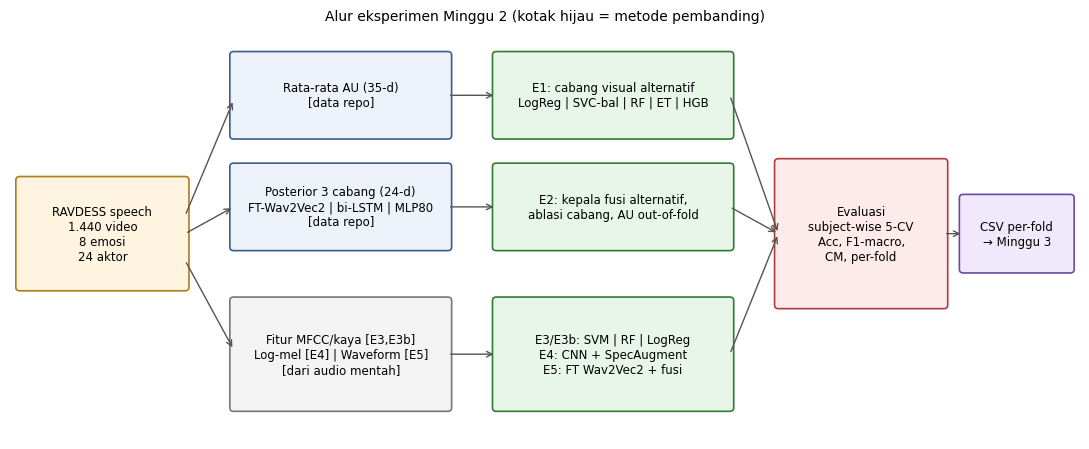

In [8]:
import os, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
warnings.filterwarnings("ignore")
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from scipy import stats
import rav_utils as u

u.set_seed()
REPO_DIR = PREP["repo"]
assert REPO_DIR, "Repo MMEmotionRecognition tidak ditemukan. Tambahkan sebagai dataset, atau aktifkan Internet lalu jalankan ulang sel Deteksi data."
os.makedirs("results", exist_ok=True)
u.env_log("results/env_log_m2.json", {"repo": os.path.basename(REPO_DIR)})

# ---- Diagram alur eksperimen ----
fig, ax = plt.subplots(figsize=(11, 4.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 4.6)
def box(x, y, w, h, t, fc="#eef3fb", ec="#3b5b92", fs=8.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=fc, ec=ec, lw=1.2))
    ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=fs)
def arr(x1, y1, x2, y2): ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#555"))
box(0.1, 1.7, 1.7, 1.2, "RAVDESS speech\n1.440 video\n8 emosi\n24 aktor", fc="#fff4e0", ec="#b07a1f")
box(2.3, 3.4, 2.2, 0.9, "Rata-rata AU (35-d)\n[data repo]")
box(2.3, 2.15, 2.2, 0.9, "Posterior 3 cabang (24-d)\nFT-Wav2Vec2 | bi-LSTM | MLP80\n[data repo]")
box(2.3, 0.35, 2.2, 1.2, "Fitur MFCC/kaya [E3,E3b]\nLog-mel [E4] | Waveform [E5]\n[dari audio mentah]", fc="#f3f3f3", ec="#777")
box(5.0, 3.4, 2.4, 0.9, "E1: cabang visual alternatif\nLogReg | SVC-bal | RF | ET | HGB", fc="#e8f5e9", ec="#2e7d32")
box(5.0, 2.15, 2.4, 0.9, "E2: kepala fusi alternatif,\nablasi cabang, AU out-of-fold", fc="#e8f5e9", ec="#2e7d32")
box(5.0, 0.35, 2.4, 1.2, "E3/E3b: SVM | RF | LogReg\nE4: CNN + SpecAugment\nE5: FT Wav2Vec2 + fusi", fc="#e8f5e9", ec="#2e7d32")
box(7.9, 1.5, 1.7, 1.6, "Evaluasi\nsubject-wise 5-CV\nAcc, F1-macro,\nCM, per-fold", fc="#fdeaea", ec="#b23b3b")
box(9.8, 1.9, 1.1, 0.8, "CSV per-fold\n→ Minggu 3", fc="#f0e9fb", ec="#6a4aa5")
for y in (3.85, 2.6, 0.95): arr(4.5, y, 5.0, y)
arr(1.8, 2.5, 2.3, 3.8); arr(1.8, 2.3, 2.3, 2.6); arr(1.8, 2.0, 2.3, 1.0)
for y in (3.85, 2.6, 0.95): arr(7.4, y, 7.9, 2.3)
arr(9.6, 2.3, 9.8, 2.3)
ax.set_title("Alur eksperimen Minggu 2 (kotak hijau = metode pembanding)", fontsize=10)
plt.tight_layout(); plt.savefig("results/flow_eksperimen_M2.png", dpi=150); plt.show()

In [9]:
config = pd.DataFrame([
 ["Baseline", "—", "Posterior 3 cabang (24-d)", "LogReg C=1", "MinMax", "Acc, F1", "Direplikasi di 01 (86,70 %)"],
 ["E1", "Optimasi/klasifier", "Rata-rata AU 35-d", "MLP80 (ref), LogReg C=10, SVC C=1 balanced, SVC C=3, RF-500 balanced, ExtraTrees-500 balanced, HistGB balanced", "MinMax (linear/SVC/MLP); tanpa (pohon)", "Acc, F1, CM", "Dijalankan"],
 ["E2a", "Arsitektur fusi", "Posterior 3 cabang", "LogReg balanced, LogReg C=10, SVC RBF, RF-300", "MinMax", "Acc, F1", "Dijalankan"],
 ["E2b", "Ablasi cabang", "Subset posterior", "LogReg C=1", "MinMax", "Acc, F1", "Dijalankan"],
 ["E2c", "Pelatihan fusi anti-bias", "Posterior audio + bi-LSTM + AU out-of-fold (GroupKFold per aktor)", "LogReg C=1", "MinMax", "Acc, F1", "Dijalankan"],
 ["E3", "Fitur beda", "MFCC+Δ+ΔΔ mean/std 240-d", "SVC RBF C=10, RF-500, LogReg C=1", "Standard", "Acc, F1, CM", "Butuh audio mentah (lihat §6)"],
 ["E4", "Arsitektur + optimasi", "Log-mel 64x251 (audio mentah)", "CNN 4 blok (32-64-128-128) + SpecAugment (2 freq, 2 waktu) + label smoothing 0,1 + AdamW/OneCycle", "Per-rekaman", "Acc, F1, CM, kurva per-epoch", "Butuh audio mentah; GPU disarankan (§6b)"],
 ["E3b", "Fitur beda + tuning", "±379 fitur audio (MFCC, log-mel, chroma, kontras, spektral, prosodi)", "SVC RBF, SelectKBest; C/gamma/k via CV-dalam per aktor", "Standard", "Acc, F1", "Butuh audio mentah (§6a)"],
 ["E5", "Optimasi pada model paper", "Waveform 16 kHz", "FT Wav2Vec2 (checkpoint sama) + resep berbeda; fusi dgn posterior visual paper", "Per-utterance", "Acc, F1, kurva, fusi", "GPU + Internet (§6c)"],
], columns=["ID", "Sumbu perbedaan", "Input", "Model / hiper-parameter", "Normalisasi", "Metrik", "Status"])
config.to_csv("results/tabel_konfigurasi_M2.csv", index=False)
config

,ID,Sumbu perbedaan,Input,Model / hiper-parameter,Normalisasi,Metrik,Status
0,Baseline,—,Posterior 3 cabang (24-d),LogReg C=1,MinMax,"Acc, F1","Direplikasi di 01 (86,70 %)"
1,E1,Optimasi/klasifier,Rata-rata AU 35-d,"MLP80 (ref), LogReg C=10, SVC C=1 balanced, SV...",MinMax (linear/SVC/MLP); tanpa (pohon),"Acc, F1, CM",Dijalankan
2,E2a,Arsitektur fusi,Posterior 3 cabang,"LogReg balanced, LogReg C=10, SVC RBF, RF-300",MinMax,"Acc, F1",Dijalankan
3,E2b,Ablasi cabang,Subset posterior,LogReg C=1,MinMax,"Acc, F1",Dijalankan
4,E2c,Pelatihan fusi anti-bias,Posterior audio + bi-LSTM + AU out-of-fold (Gr...,LogReg C=1,MinMax,"Acc, F1",Dijalankan
5,E3,Fitur beda,MFCC+Δ+ΔΔ mean/std 240-d,"SVC RBF C=10, RF-500, LogReg C=1",Standard,"Acc, F1, CM",Butuh audio mentah (lihat §6)
6,E4,Arsitektur + optimasi,Log-mel 64x251 (audio mentah),CNN 4 blok (32-64-128-128) + SpecAugment (2 fr...,Per-rekaman,"Acc, F1, CM, kurva per-epoch",Butuh audio mentah; GPU disarankan (§6b)
7,E3b,Fitur beda + tuning,"±379 fitur audio (MFCC, log-mel, chroma, kontr...","SVC RBF, SelectKBest; C/gamma/k via CV-dalam p...",Standard,"Acc, F1",Butuh audio mentah (§6a)
8,E5,Optimasi pada model paper,Waveform 16 kHz,FT Wav2Vec2 (checkpoint sama) + resep berbeda;...,Per-utterance,"Acc, F1, kurva, fusi",GPU + Internet (§6c)


## 3. E1 — Cabang visual alternatif pada rata-rata AU
**Pertanyaan:** apakah MLP80 (baseline) benar-benar lebih baik dari pengklasifikasi klasik/ensemble pada 35 fitur AU rata-rata?
**Motivasi desain:** data kecil (≈1.150 sampel latih/fold, 35 fitur) — model berbasis pohon & SVM biasanya kompetitif; `class_weight="balanced"` menangani kelas *neutral* yang hanya setengah jumlah kelas lain.

In [10]:
au, au_feat = u.load_au_avg(REPO_DIR)
E1 = {
 "MLP80 (baseline)":          (lambda: MLPClassifier((80,), random_state=u.SEED), "minmax"),
 "LogReg C=10":               (lambda: LogisticRegression(C=10, max_iter=10000, random_state=u.SEED), "minmax"),
 "SVC C=1 balanced":          (lambda: SVC(C=1, class_weight="balanced", random_state=u.SEED), "minmax"),
 "SVC C=3":                   (lambda: SVC(C=3, random_state=u.SEED), "minmax"),
 "RandomForest-500 balanced": (lambda: RandomForestClassifier(500, class_weight="balanced", random_state=u.SEED, n_jobs=-1), None),
 "ExtraTrees-500 balanced":   (lambda: ExtraTreesClassifier(500, class_weight="balanced", random_state=u.SEED, n_jobs=-1), None),
 "HistGB balanced":           (lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, class_weight="balanced", random_state=u.SEED), None),
}
rows, long_rows, e1_res = [], [], {}
for name, (mk, norm) in E1.items():
    r = u.run_cv(au, au_feat, mk, norm); e1_res[name] = r
    rows.append({"Model": name, "Acc (%)": round(np.mean(r["acc"]), 2), "±CI95": round(u.ci95(r["acc"]), 2),
                 "F1-macro (%)": round(np.mean(r["f1"]), 2), "Acc per fold": [round(a, 1) for a in r["acc"]]})
    long_rows += [{"experiment": f"E1_{name}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
tabE1 = pd.DataFrame(rows); tabE1["Δ Acc vs MLP80"] = (tabE1["Acc (%)"] - tabE1["Acc (%)"].iloc[0]).round(2)
u.append_results("results/results_long_m2.csv", long_rows); tabE1.to_csv("results/tabel_E1.csv", index=False)
tabE1

,Model,Acc (%),±CI95,F1-macro (%),Acc per fold,Δ Acc vs MLP80
0,MLP80 (baseline),60.22,2.53,59.60,"[61.3, 58.7, 61.0, 64.7, 55.4]",0.00
1,LogReg C=10,58.75,2.54,57.98,"[58.0, 58.7, 61.3, 62.0, 53.8]",-1.47
2,SVC C=1 balanced,58.98,2.54,58.23,"[59.0, 60.3, 63.7, 55.7, 56.2]",-1.24
3,SVC C=3,58.33,2.55,57.92,"[57.7, 58.0, 61.7, 57.7, 56.7]",-1.89
4,RandomForest-500 balanced,58.45,2.55,57.42,"[61.3, 58.0, 60.7, 54.3, 57.9]",-1.77
5,ExtraTrees-500 balanced,59.13,2.54,57.95,"[61.0, 57.3, 60.0, 55.7, 61.7]",-1.09
6,HistGB balanced,53.85,2.57,52.63,"[54.0, 54.7, 57.0, 52.3, 51.2]",-6.37


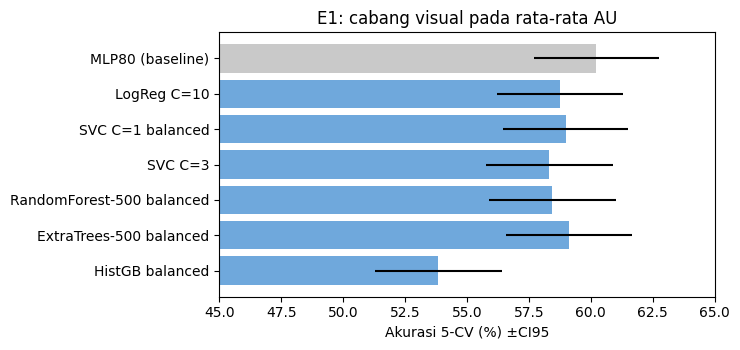

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
t = tabE1.iloc[::-1]
ax.barh(t["Model"], t["Acc (%)"], xerr=t["±CI95"], color=["#c9c9c9" if "baseline" in m else "#6fa8dc" for m in t["Model"]])
ax.set_xlim(45, 65); ax.set_xlabel("Akurasi 5-CV (%) ±CI95"); ax.set_title("E1: cabang visual pada rata-rata AU")
plt.tight_layout(); plt.savefig("results/E1_bar.png", dpi=150); plt.show()

**Cara membaca:** kecuali HistGB (−6,4 poin), semua pengklasifikasi berada dalam ±2 poin dari MLP80, yaitu di dalam CI95 (±2,5). Pada fitur AU rata-rata yang hanya 35-d, ganti pengklasifikasi tidak banyak membantu; bottleneck-nya kemungkinan di fitur (rata-rata menghapus informasi temporal). Untuk kesimpulan formal, tunggu uji berpasangan antar fold di Minggu 3.

## 4. E2 — Fusi: kepala alternatif, ablasi, dan cabang AU *out-of-fold*
Data: posterior rilisan penulis (`data/posteriors`). **Keterbatasan:** cabang audio (FT-Wav2Vec2) dan bi-LSTM tidak bisa dilatih ulang di CPU, jadi E2 hanya mengubah **tahap fusi** dan **cabang AU statis**.

In [12]:
base = u.fusion_cv(REPO_DIR)
LR = lambda **k: (lambda: LogisticRegression(max_iter=10000, random_state=u.SEED, **k))
E2a = {
 "Baseline: LogReg C=1":      None,
 "LogReg balanced":           LR(C=1, class_weight="balanced"),
 "LogReg C=10":               LR(C=10),
 "SVC RBF C=1":               lambda: SVC(C=1, random_state=u.SEED),
 "RandomForest-300":          lambda: RandomForestClassifier(300, random_state=u.SEED, n_jobs=-1),
}
rows, long_rows, e2_res = [], [], {}
for name, mk in E2a.items():
    r = base if mk is None else u.fusion_cv(REPO_DIR, make_clf=mk); e2_res[name] = r
    rows.append({"Kepala fusi": name, "Acc (%)": round(np.mean(r["acc"]), 2), "±CI95": round(u.ci95(r["acc"]), 2),
                 "F1-macro (%)": round(np.mean(r["f1"]), 2), "Acc per fold": [round(a, 1) for a in r["acc"]]})
    long_rows += [{"experiment": f"E2a_{name}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
tabE2a = pd.DataFrame(rows); tabE2a["Δ Acc vs baseline"] = (tabE2a["Acc (%)"] - 86.70).round(2)
u.append_results("results/results_long_m2.csv", long_rows); tabE2a.to_csv("results/tabel_E2a.csv", index=False)
tabE2a

,Kepala fusi,Acc (%),±CI95,F1-macro (%),Acc per fold,Δ Acc vs baseline
0,Baseline: LogReg C=1,86.70,1.75,86.58,"[88.7, 88.7, 84.7, 85.7, 85.8]",0.00
1,LogReg balanced,86.55,1.76,86.44,"[88.7, 88.3, 85.0, 85.3, 85.4]",-0.15
2,LogReg C=10,86.15,1.78,85.88,"[87.7, 86.7, 85.7, 85.3, 85.4]",-0.55
3,SVC RBF C=1,84.68,1.86,84.53,"[85.0, 87.3, 83.3, 84.0, 83.8]",-2.02
4,RandomForest-300,83.28,1.93,83.20,"[85.3, 87.7, 81.0, 83.7, 78.8]",-3.42


In [13]:
# E2b — ablasi cabang (apa kontribusi tiap modalitas?)
ABL = {"audio saja": ("audio",), "bi-LSTM saja": ("bilstm",), "MLP80 saja": ("mlp",),
       "audio + bi-LSTM": ("audio", "bilstm"), "audio + MLP80": ("audio", "mlp"), "bi-LSTM + MLP80": ("bilstm", "mlp"),
       "ketiganya (baseline)": ("audio", "bilstm", "mlp")}
rows, long_rows = [], []
for name, br in ABL.items():
    r = u.fusion_cv(REPO_DIR, branches=br)
    rows.append({"Cabang": name, "Acc (%)": round(np.mean(r["acc"]), 2), "F1-macro (%)": round(np.mean(r["f1"]), 2),
                 "Acc per fold": [round(a, 1) for a in r["acc"]]})
    long_rows += [{"experiment": f"E2b_{name}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
tabE2b = pd.DataFrame(rows)
u.append_results("results/results_long_m2.csv", long_rows); tabE2b.to_csv("results/tabel_E2b.csv", index=False)
tabE2b

,Cabang,Acc (%),F1-macro (%),Acc per fold
0,audio saja,81.22,80.65,"[85.7, 81.3, 79.3, 82.7, 77.1]"
1,bi-LSTM saja,60.55,59.94,"[64.7, 59.0, 64.7, 59.0, 55.4]"
2,MLP80 saja,59.42,59.04,"[60.3, 58.3, 60.7, 64.0, 53.8]"
3,audio + bi-LSTM,85.40,85.08,"[87.3, 88.0, 83.0, 83.7, 85.0]"
4,audio + MLP80,84.92,84.72,"[86.7, 88.7, 81.7, 84.7, 82.9]"
5,bi-LSTM + MLP80,60.57,60.15,"[64.0, 58.7, 64.3, 60.0, 55.8]"
6,ketiganya (baseline),86.70,86.58,"[88.7, 88.7, 84.7, 85.7, 85.8]"


In [14]:
# E2c — cabang AU dengan posterior out-of-fold (tidak in-sample seperti baseline)
rows, long_rows = [], []
for mname, mk in [("MLP80", lambda: MLPClassifier((80,), random_state=u.SEED)),
                  ("SVC prob.", lambda: SVC(C=1, probability=True, random_state=u.SEED))]:
    mod = u.make_oof_branch(REPO_DIR, mk)
    for desc, br in [("mengganti MLP80 rilisan", ("audio", "bilstm", "au_oof")), ("ditambah sbg cabang ke-4", ("audio", "bilstm", "mlp", "au_oof"))]:
        r = u.fusion_cv(REPO_DIR, branches=br, modify=mod); key = f"{mname} OOF — {desc}"
        rows.append({"Varian": key, "Acc (%)": round(np.mean(r["acc"]), 2), "F1-macro (%)": round(np.mean(r["f1"]), 2),
                     "Acc per fold": [round(a, 1) for a in r["acc"]]})
        long_rows += [{"experiment": f"E2c_{key}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
        e2_res[key] = r
tabE2c = pd.DataFrame(rows); tabE2c["Δ Acc vs baseline"] = (tabE2c["Acc (%)"] - 86.70).round(2)
u.append_results("results/results_long_m2.csv", long_rows); tabE2c.to_csv("results/tabel_E2c.csv", index=False)
tabE2c

,Varian,Acc (%),F1-macro (%),Acc per fold,Δ Acc vs baseline
0,MLP80 OOF — mengganti MLP80 rilisan,86.50,86.25,"[87.7, 88.7, 84.7, 85.7, 85.8]",-0.20
1,MLP80 OOF — ditambah sbg cabang ke-4,86.72,86.51,"[88.3, 88.7, 85.0, 85.3, 86.2]",0.02
2,SVC prob. OOF — mengganti MLP80 rilisan,86.22,85.96,"[87.0, 88.7, 85.3, 84.7, 85.4]",-0.48
3,SVC prob. OOF — ditambah sbg cabang ke-4,86.97,86.75,"[88.7, 89.0, 85.3, 86.0, 85.8]",0.27


In [15]:
# Pratinjau uji berpasangan (BUKAN kesimpulan final — uji resmi di Minggu 3). n = 5 fold => daya uji rendah.
rows = []
for name, r in e2_res.items():
    if name.startswith("Baseline"): continue
    d = np.array(r["acc"]) - np.array(base["acc"])
    t, p = stats.ttest_rel(r["acc"], base["acc"])
    rows.append({"Varian": name, "Δ rata-rata (poin)": round(d.mean(), 2), "fold lebih baik": f"{(d > 0).sum()}/5", "p (paired t)": round(p, 3)})
pd.DataFrame(rows)

,Varian,Δ rata-rata (poin),fold lebih baik,p (paired t)
0,LogReg balanced,-0.15,1/5,0.346
1,LogReg C=10,-0.55,1/5,0.323
2,SVC RBF C=1,-2.02,0/5,0.010
3,RandomForest-300,-3.42,0/5,0.030
4,MLP80 OOF — mengganti MLP80 rilisan,-0.20,0/5,0.374
5,MLP80 OOF — ditambah sbg cabang ke-4,0.02,2/5,0.922
6,SVC prob. OOF — mengganti MLP80 rilisan,-0.48,1/5,0.295
7,SVC prob. OOF — ditambah sbg cabang ke-4,0.27,3/5,0.099


**Temuan sementara E2:** (i) ablasi menunjukkan modalitas audio menyumbang hampir semua akurasi (≈81 %), sedangkan menambah AU menaikkan ke ≈86,7 %; (ii) LogReg dengan variasi C/class-weight dan AU *out-of-fold* hanya menggeser hasil dalam kisaran ±0,5 poin — di dalam CI 95 % (±1,8), jadi belum ada bukti perbaikan; (iii) SVC dan Random Forest sebagai kepala fusi justru lebih rendah (−2,0 dan −3,5 poin; p < 0,05 pada pratinjau tanpa koreksi perbandingan ganda), artinya kepala linear sederhana memang cocok untuk input posterior 24-d.

## 5. Pemilihan kandidat untuk Minggu 3
Aturan: kandidat terbaik per keluarga (baseline dikeluarkan) menurut **F1-macro**, lalu dibandingkan dengan baseline memakai uji berpasangan di Minggu 3. Kandidat E1 dibandingkan dengan **MLP80 (60,22 %)**; kandidat E2 dengan **fusi baseline (86,70 %)**. Catatan: memilih kandidat dari hasil CV yang sama dengan evaluasinya membawa sedikit bias seleksi — sebutkan di keterbatasan artikel.

In [16]:
cands = pd.concat([
    tabE1.assign(Keluarga="E1 (visual)")[["Keluarga", "Model", "Acc (%)", "F1-macro (%)"]],
    tabE2a.rename(columns={"Kepala fusi": "Model"}).assign(Keluarga="E2a (kepala fusi)")[["Keluarga", "Model", "Acc (%)", "F1-macro (%)"]],
    tabE2c.rename(columns={"Varian": "Model"}).assign(Keluarga="E2c (AU out-of-fold)")[["Keluarga", "Model", "Acc (%)", "F1-macro (%)"]],
])
cands = cands[~cands["Model"].str.contains("baseline", case=False)]          # baseline bukan pembanding
best = cands.sort_values("F1-macro (%)", ascending=False).groupby("Keluarga").head(1).sort_values("Keluarga")
best.to_csv("results/kandidat_M3.csv", index=False)
best

,Keluarga,Model,Acc (%),F1-macro (%)
2,E1 (visual),SVC C=1 balanced,58.98,58.23
1,E2a (kepala fusi),LogReg balanced,86.55,86.44
3,E2c (AU out-of-fold),SVC prob. OOF — ditambah sbg cabang ke-4,86.97,86.75


## 6. E3 — MFCC + pengklasifikasi klasik (audio mentah dari dataset Kaggle)
Memakai file `.wav` yang ditemukan sel Deteksi data; kanal dipilih lewat `E3_CHANNEL` (`"speech"` default = Audio_Speech, sebanding dengan paper; `"song"` = Audio_Song, TIDAK sebanding) (nama `03-…` dipetakan ke `01-…`, rekaman yang sama dengan video AV di paper). Ekstraksi dilakukan paralel dan di-*cache* ke `results/mfcc_features.csv`. Jika audio tidak lengkap 1.440 rekaman, sel menampilkan peringatan dan **tidak** menyimpan skor ke `results_long_m2.csv` (agar tidak mencemari uji Minggu 3).

In [17]:
import audio_features as af
from sklearn.svm import SVC
E3_CHANNEL = "speech"      # "speech" = Audio_Speech (1440, sebanding dengan paper) | "song" = Audio_Song (1012, TIDAK sebanding)
EXPECTED_N = {"speech": 1440, "song": 1012}
E3_SUFFIX = "" if E3_CHANNEL == "speech" else "_song"
aud = PREP["audio_speech" if E3_CHANNEL == "speech" else "audio_song"]
if aud is None or len(aud) == 0:
    print(f"E3 DILEWATI: tidak ada audio '{E3_CHANNEL}' di data yang terpasang.")
    tabE3 = None
else:
    n = len(aud); print(f"Kanal: {E3_CHANNEL} | audio dipakai: {n} rekaman (target {EXPECTED_N[E3_CHANNEL]})")
    mf = af.extract_from_df(aud, cache=f"results/mfcc_{E3_CHANNEL}.csv")
    mf_feat = [c for c in mf.columns if c.startswith("mfcc_")]
    E3 = {"SVC RBF C=10":     lambda: SVC(C=10, random_state=u.SEED),
          "RandomForest-500": lambda: RandomForestClassifier(500, random_state=u.SEED, n_jobs=-1),
          "LogReg C=1":       lambda: LogisticRegression(C=1, max_iter=10000, random_state=u.SEED)}
    rows, long_rows = [], []
    for name, mk in E3.items():
        r = u.run_cv(mf, mf_feat, mk, "standard")
        rows.append({"Model": name, "Acc (%)": round(np.mean(r["acc"]), 2), "±CI95": round(u.ci95(r["acc"], n_total=n), 2),
                     "F1-macro (%)": round(np.mean(r["f1"]), 2), "Acc per fold": [round(a, 1) for a in r["acc"]]})
        long_rows += [{"experiment": f"E3_{name}{E3_SUFFIX}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
    tabE3 = pd.DataFrame(rows)
    if n == EXPECTED_N[E3_CHANNEL]:
        u.append_results("results/results_long_m2.csv", long_rows); tabE3.to_csv(f"results/tabel_E3{E3_SUFFIX}.csv", index=False)
    else:
        print(f"PERINGATAN: hanya {n}/{EXPECTED_N[E3_CHANNEL]} rekaman -> hasil E3 TIDAK valid & tidak disimpan.")
    if E3_CHANNEL == "song":
        print("CATATAN: song tidak sebanding dengan paper (speech, 8 emosi) -> jangan dihitung sebagai 'di atas paper'.")
tabE3

Kanal: speech | audio dipakai: 1440 rekaman (target 1440)


,Model,Acc (%),±CI95,F1-macro (%),Acc per fold
0,SVC RBF C=10,51.07,2.58,49.61,"[53.7, 54.0, 51.3, 49.7, 46.7]"
1,RandomForest-500,48.03,2.58,44.22,"[50.7, 47.0, 43.3, 56.7, 42.5]"
2,LogReg C=1,43.40,2.56,41.45,"[44.7, 46.3, 45.7, 40.3, 40.0]"


**Pembanding yang adil untuk E3:** bandingkan dengan baseline *audio saja* (FE-Wav2Vec MLP80 = 56,53 % dan FT-Wav2Vec2 = 81,82 % di paper), bukan dengan fusi 86,70 %, karena E3 hanya memakai audio.

## 6a. E3b — E3 yang diperbaiki: fitur lebih kaya + tuning tanpa menyentuh fold uji
**Apa yang diperbaiki dari E3** (E3 hanya MFCC 240-d dengan hiper-parameter tetap):
1. **Fitur lebih kaya (±379-d):** MFCC+Δ+ΔΔ, log-mel, chroma, spectral contrast, centroid/bandwidth/rolloff/flatness, ZCR, RMS, plus prosodi (statistik F0, rasio bersuara, durasi).
2. **Hiper-parameter dipilih lewat CV-dalam per aktor** (GroupKFold di data latih): C, gamma, dan jumlah fitur terbaik (SelectKBest). Fold uji **tidak** dipakai memilih apa pun.

**Tidak memakai normalisasi per-aktor:** teknik itu memakai statistik rekaman aktor uji (transduktif) dan tidak dipakai paper, jadi sengaja tidak disertakan agar protokol tetap sama dengan paper.

**Pembanding yang adil:** baris *audio feature-extraction* paper (Tabel 1: SVC 53,12 %; MLP80 **56,53 %**). Fitur klasik **tidak realistis** untuk mengalahkan Wav2Vec2 fine-tuned (81,82 %) atau fusi (86,70 %); hasilnya hanya boleh diklaim "di atas paper" terhadap kelompok metode yang sepadan, dan harus diuji (selisih > CI, konsisten antar-fold).

In [18]:
E3B_CHANNEL = "speech"     # "speech" = sebanding dengan paper | "song" = TIDAK sebanding
E3B_SUFFIX = "" if E3B_CHANNEL == "speech" else "_song"
aud3b = PREP["audio_speech" if E3B_CHANNEL == "speech" else "audio_song"]
tabE3b = None
if aud3b is None or len(aud3b) == 0:
    print(f"E3b DILEWATI: tidak ada audio '{E3B_CHANNEL}'.")
else:
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.feature_selection import SelectKBest, f_classif
    n = len(aud3b); print(f"Kanal: {E3B_CHANNEL} | {n} rekaman (target {EXPECTED_N[E3B_CHANNEL]})")
    rich = af.extract_rich_from_df(aud3b, cache=f"results/rich_{E3B_CHANNEL}.csv")
    rfeat = [c for c in rich.columns if c.startswith("rich_")]; print("Jumlah fitur:", len(rfeat))
    pipe = Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(f_classif)), ("clf", SVC(random_state=u.SEED))])
    grid = {"sel__k": [100, 200, "all"], "clf__C": [1, 10, 100], "clf__gamma": ["scale", 1e-3, 3e-3]}
    rows, long_rows = [], []
    for label, data in [("E3b SVC (fitur kaya + tuning CV-dalam)", rich)]:
        r = u.run_cv_grid(data, rfeat, pipe, grid)
        rows.append({"Model": label, "Acc (%)": round(np.mean(r["acc"]), 2), "±CI95": round(u.ci95(r["acc"], n_total=n), 2),
                     "F1-macro (%)": round(np.mean(r["f1"]), 2), "Acc per fold": [round(a, 1) for a in r["acc"]]})
        key = "E3b_SVC_rich"
        long_rows += [{"experiment": f"{key}{E3B_SUFFIX}", "fold": f, "acc": r["acc"][f], "f1_macro": r["f1"][f]} for f in range(5)]
        print(label, "-> hiper-parameter terpilih per fold:", r["best_params"])
    tabE3b = pd.DataFrame(rows)
    if n == EXPECTED_N[E3B_CHANNEL]:
        u.append_results("results/results_long_m2.csv", long_rows); tabE3b.to_csv(f"results/tabel_E3b{E3B_SUFFIX}.csv", index=False)
    else:
        print(f"PERINGATAN: hanya {n}/{EXPECTED_N[E3B_CHANNEL]} rekaman -> hasil E3b TIDAK valid & tidak disimpan.")
    print("Acuan paper (audio, feature-extraction): SVC 53,12 % | MLP80 56,53 %   —   FT-Wav2Vec2: 81,82 % (bukan pembanding sepadan)")
tabE3b

Kanal: speech | 1440 rekaman (target 1440)
Jumlah fitur: 379
E3b SVC (fitur kaya + tuning CV-dalam) -> hiper-parameter terpilih per fold: [{'clf__C': 10, 'clf__gamma': 0.001, 'sel__k': 'all'}, {'clf__C': 100, 'clf__gamma': 0.003, 'sel__k': 200}, {'clf__C': 10, 'clf__gamma': 0.001, 'sel__k': 'all'}, {'clf__C': 10, 'clf__gamma': 'scale', 'sel__k': 'all'}, {'clf__C': 10, 'clf__gamma': 0.003, 'sel__k': 200}]
Acuan paper (audio, feature-extraction): SVC 53,12 % | MLP80 56,53 %   —   FT-Wav2Vec2: 81,82 % (bukan pembanding sepadan)


,Model,Acc (%),±CI95,F1-macro (%),Acc per fold
0,E3b SVC (fitur kaya + tuning CV-dalam),53.05,2.58,51.71,"[55.0, 51.3, 52.7, 51.7, 54.6]"


## 6b. E4 — CNN kecil pada log-mel spectrogram + SpecAugment
**Sumbu perbedaan:** arsitektur (CNN dari nol, tanpa transformer pra-latih) + optimasi (augmentasi SpecAugment, label smoothing, jadwal learning-rate OneCycle).

**Desain:** audio 16 kHz mono, hening di tepi dibuang, dipotong/dipad ke 4 detik → log-mel 64×251 → normalisasi per-rekaman → 4 blok Conv-BN-ReLU-MaxPool (32-64-128-128) → global average pooling → dropout 0,3 → 8 kelas. Augmentasi (hanya data latih): 2 masking frekuensi (≤10 mel) + 2 masking waktu (≤30 frame).

**Aturan evaluasi:** jumlah epoch tetap; **tidak ada early-stopping atau pemilihan epoch memakai fold uji** — yang dilaporkan adalah epoch terakhir. Kurva per-epoch disimpan (`results/history_E4.csv`) untuk analisis "kurva validasi" di Minggu 3 (di sini fold uji hanya berfungsi sebagai pemantau).

**Kanal data (`E4_CHANNEL`):** `"song"` (default sesuai permintaan: E4 hanya memakai Audio_Song, terpisah dari speech) atau `"speech"`. Song di RAVDESS = 1.012 rekaman, 23 aktor, tanpa sebagian emosi → angkanya **tidak sebanding** dengan paper (speech, 8 emosi) dan **tidak boleh dihitung sebagai "di atas paper"**; hasilnya disimpan terpisah (akhiran `_song`). Untuk pembanding yang sebanding, set `"speech"` (baseline audio-saja: 81,82 % FT-Wav2Vec2; 56,53 % embedding feature-encoder; bukan fusi 86,70 %).

**Waktu:** GPU T4 ≈ beberapa menit untuk 5 fold × 40 epoch; CPU jauh lebih lama (otomatis 15 epoch). Hasil GPU tidak bit-per-bit sama antar-run (cuDNN non-deterministik), jadi angka bisa bergeser sedikit.

In [19]:
import cnn_audio as ca
E4_CHANNEL = "song"        # "song" = Audio_Song (1012 rekaman, TIDAK sebanding dengan paper) | "speech" = Audio_Speech (1440, sebanding dengan paper)
EXPECTED_N = {"speech": 1440, "song": 1012}
E4_SUFFIX = "" if E4_CHANNEL == "speech" else "_song"
aud = PREP["audio_speech" if E4_CHANNEL == "speech" else "audio_song"]
if aud is None or len(aud) == 0:
    print(f"E4 DILEWATI: tidak ada audio '{E4_CHANNEL}' di data yang terpasang.")
    X4 = None
else:
    X4, y4, act4, names4 = ca.extract_logmel(aud, cache=f"cache/logmel_{E4_CHANNEL}.npz")      # paralel, di-cache per kanal
    print(f"Kanal: {E4_CHANNEL} | Log-mel: {X4.shape} (rekaman, mel, frame) | aktor: {len(set(act4))} | kelas emosi: {sorted(set(y4.tolist()))}")
    if E4_CHANNEL == "song":
        print("CATATAN: song hanya punya sebagian emosi & 23 aktor -> akurasinya TIDAK boleh dibandingkan dengan angka paper (speech, 8 emosi).")

Kanal: song | Log-mel: (1012, 64, 251) (rekaman, mel, frame) | aktor: 23 | kelas emosi: [0, 1, 2, 3, 4, 5]
CATATAN: song hanya punya sebagian emosi & 23 aktor -> akurasinya TIDAK boleh dibandingkan dengan angka paper (speech, 8 emosi).


In [20]:
import time, torch
tabE4 = None
if X4 is None:
    print("E4 DILEWATI.")
else:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    EPOCHS = 40 if dev == "cuda" else 15
    print(f"Device: {dev} | epoch: {EPOCHS}" + ("" if dev == "cuda" else "   (CPU lambat — aktifkan GPU di Settings untuk 40 epoch)"))
    t0 = time.time()
    r4, hist4 = ca.run_cnn_cv(X4, y4, act4, epochs=EPOCHS, device=dev)
    print(f"Selesai: {(time.time() - t0) / 60:.1f} menit")
    tabE4 = pd.DataFrame([{"Model": f"CNN log-mel + SpecAugment ({EPOCHS} epoch)", "Acc (%)": round(np.mean(r4["acc"]), 2),
                           "±CI95": round(u.ci95(r4["acc"], n_total=len(X4)), 2), "F1-macro (%)": round(np.mean(r4["f1"]), 2),
                           "Acc per fold": [round(a, 1) for a in r4["acc"]]}])
    if len(X4) == EXPECTED_N[E4_CHANNEL]:
        u.append_results("results/results_long_m2.csv", [{"experiment": f"E4_CNN_logmel_SpecAugment{E4_SUFFIX}", "fold": f, "acc": r4["acc"][f], "f1_macro": r4["f1"][f]} for f in range(5)])
        hist4.to_csv(f"results/history_E4{E4_SUFFIX}.csv", index=False); tabE4.to_csv(f"results/tabel_E4{E4_SUFFIX}.csv", index=False)
    else:
        print(f"PERINGATAN: hanya {len(X4)}/{EXPECTED_N[E4_CHANNEL]} rekaman -> hasil E4 TIDAK valid & tidak disimpan.")
tabE4

Device: cuda | epoch: 40
fold 0 ep   1/40 train_loss 2.047 | test_loss 2.146 test_acc 20.5
fold 0 ep   5/40 train_loss 1.573 | test_loss 1.498 test_acc 36.8
fold 0 ep  10/40 train_loss 1.311 | test_loss 2.929 test_acc 20.5
fold 0 ep  15/40 train_loss 1.081 | test_loss 1.343 test_acc 53.6
fold 0 ep  20/40 train_loss 0.993 | test_loss 1.043 test_acc 67.7
fold 0 ep  25/40 train_loss 0.907 | test_loss 0.843 test_acc 66.4
fold 0 ep  30/40 train_loss 0.866 | test_loss 0.780 test_acc 67.7
fold 0 ep  35/40 train_loss 0.810 | test_loss 0.464 test_acc 81.4
fold 0 ep  40/40 train_loss 0.787 | test_loss 0.482 test_acc 81.4
fold 1 ep   1/40 train_loss 1.994 | test_loss 1.994 test_acc 22.2
fold 1 ep   5/40 train_loss 1.569 | test_loss 1.625 test_acc 35.8
fold 1 ep  10/40 train_loss 1.338 | test_loss 2.495 test_acc 26.7
fold 1 ep  15/40 train_loss 1.142 | test_loss 1.512 test_acc 50.0
fold 1 ep  20/40 train_loss 1.033 | test_loss 1.387 test_acc 55.1
fold 1 ep  25/40 train_loss 0.950 | test_loss 0.804

,Model,Acc (%),±CI95,F1-macro (%),Acc per fold
0,CNN log-mel + SpecAugment (40 epoch),82.02,2.37,83.35,"[81.4, 83.5, 74.1, 88.2, 83.0]"


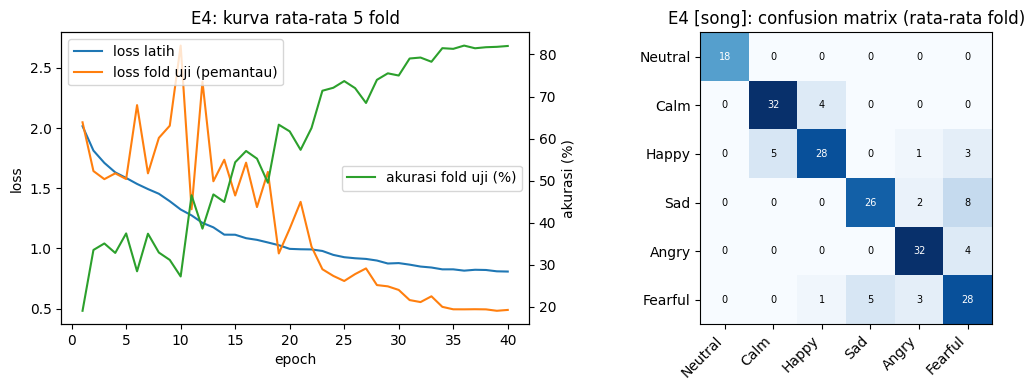

In [21]:
if tabE4 is not None:
    from sklearn.metrics import confusion_matrix
    nm_all = ["Neutral", "Calm", "Happy", "Sad", "Angry", "Fearful", "Disgusted", "Surprised"]
    labs = sorted(set(y4.tolist())); nm = [nm_all[i] for i in labs]
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    g = hist4.groupby("epoch")[["train_loss", "test_loss", "test_acc"]].mean()
    axs[0].plot(g.index, g.train_loss, label="loss latih"); axs[0].plot(g.index, g.test_loss, label="loss fold uji (pemantau)")
    a2 = axs[0].twinx(); a2.plot(g.index, g.test_acc, color="tab:green", label="akurasi fold uji (%)"); a2.set_ylabel("akurasi (%)")
    axs[0].set_xlabel("epoch"); axs[0].set_ylabel("loss"); axs[0].legend(loc="upper left"); a2.legend(loc="center right")
    axs[0].set_title("E4: kurva rata-rata 5 fold")
    cm = sum(confusion_matrix(t, p, labels=labs) for t, p in zip(r4["yt_list"], r4["yp_list"])) / 5
    axs[1].imshow(cm.round(), cmap="Blues"); axs[1].set_xticks(range(len(labs))); axs[1].set_yticks(range(len(labs)))
    axs[1].set_xticklabels(nm, rotation=45, ha="right"); axs[1].set_yticklabels(nm)
    for i in range(len(labs)):
        for j in range(len(labs)):
            axs[1].text(j, i, int(round(cm[i, j])), ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 15 else "black")
    axs[1].set_title(f"E4 [{E4_CHANNEL}]: confusion matrix (rata-rata fold)")
    plt.tight_layout(); plt.savefig(f"results/E4_kurva_cm{E4_SUFFIX}.png", dpi=150); plt.show()

In [22]:
# OPSIONAL (waktu ~2x): ablasi "tanpa SpecAugment" untuk mengisolasi efek augmentasi. Ubah ke True untuk menjalankan.
RUN_ABLATION_NOAUG = False
if RUN_ABLATION_NOAUG and X4 is not None:
    r4n, h4n = ca.run_cnn_cv(X4, y4, act4, epochs=EPOCHS, device=dev, augment=False)
    print(f"Tanpa SpecAugment: acc {np.mean(r4n['acc']):.2f} % | F1-macro {np.mean(r4n['f1']):.2f} %  (dengan: {np.mean(r4['acc']):.2f} %)")
    if len(X4) == EXPECTED_N[E4_CHANNEL]:
        u.append_results("results/results_long_m2.csv", [{"experiment": f"E4_CNN_logmel_noAug{E4_SUFFIX}", "fold": f, "acc": r4n["acc"][f], "f1_macro": r4n["f1"][f]} for f in range(5)])

## 6c. E5 — Fine-tuning Wav2Vec2 (model SAMA dengan paper) dengan resep optimasi berbeda + fusi
**Syarat dosen:** model pra-latih tidak diganti (`jonatasgrosman/wav2vec2-large-xlsr-53-english`). Yang berbeda hanya resep optimasi: LR terpisah (backbone kecil, head besar) + warmup + cosine decay, label smoothing, rata-rata berbobot semua lapisan, masked mean-pooling, augmentasi derau/potong tepi, gradient clipping. Yang sama: CNN encoder dibekukan, pooling + MLP (1024→tanh→8), fold subject-wise, 1.440 speech.

**Pembanding:** audio-saja vs **81,82 %**, dan **fusi** (audio E5 + posterior visual paper) vs **86,70 %**.

⚠ **Temuan protokol paper:** di kode penulis, fold uji dipakai sebagai eval-set dengan `load_best_model_at_end=True` (`metric_for_best_model="eval_accuracy"`) → 81,82 % dan posterior audio-nya dipilih memakai fold uji (optimistis). Di sini dilaporkan **epoch terakhir (bersih, angka utama)** dan epoch terbaik pada fold uji (cara paper; hanya untuk perbandingan). Koreksi: teks paper menulis LR 0,001, kode penulis memakai 1e-4, batch 4×akumulasi 2, 10 epoch.

**Aturan:** tetapkan resep di sel konfigurasi **sebelum** melihat hasil; mengubahnya setelah melihat akurasi fold uji = tuning pada data uji (tulis jujur di laporan).

**Syarat:** Accelerator **GPU**, Internet **On** (unduh model). Waktu belum kuukur di GPU sungguhan (bisa berjam-jam); fold selesai tersimpan di `results/e5/` dan dilewati saat dijalankan ulang (atur `FOLDS_TO_RUN` untuk membagi ke beberapa sesi). Set `RUN_E5 = False` untuk melewati seluruh bagian ini.

### 1. Konfigurasi (tetapkan SEBELUM melihat hasil)

In [23]:
import torch
import w2v_finetune as wf
RUN_E5 = True            # False = lewati seluruh bagian E5
SMOKE_TEST = False          # True = model acak kecil, 1 epoch: HANYA mengecek pipeline jalan (angka tidak bermakna, tidak disimpan ke results_long)
FOLDS_TO_RUN = [0, 1, 2, 3, 4]
dev = "cuda" if torch.cuda.is_available() else "cpu"
cfg = dict(wf.DEFAULT_CFG)                      # epochs=15, bs=4 x accum 2, lr_backbone=3e-5, lr_head=1e-3, label_smoothing=0.1, ...
model_config, OUT_DIR = None, "results/e5"
if SMOKE_TEST:
    from transformers import Wav2Vec2Config
    model_config = Wav2Vec2Config(hidden_size=32, num_hidden_layers=2, num_attention_heads=2, intermediate_size=64, conv_dim=(16, 16, 16),
        conv_stride=(5, 2, 2), conv_kernel=(10, 3, 3), feat_extract_norm="layer", do_stable_layer_norm=True, num_conv_pos_embeddings=16,
        num_conv_pos_embedding_groups=2, mask_time_prob=0.05, layerdrop=0.0)
    cfg.update(pretrained=False, epochs=1, bs=8, accum=1); OUT_DIR = "results/e5_smoke"
print("Device:", dev, "| SMOKE_TEST:", SMOKE_TEST); print(cfg)
if dev == "cpu" and not SMOKE_TEST:
    print("PERINGATAN: tanpa GPU, fine-tuning model besar tidak praktis. Aktifkan GPU di Settings.")
E5_ACTIVE = RUN_E5 and (dev == "cuda" or SMOKE_TEST)
if RUN_E5 and not E5_ACTIVE:
    print("E5 dilewati: tidak ada GPU (Settings -> Accelerator). Set SMOKE_TEST=True untuk uji pipeline tanpa GPU.")

Device: cuda | SMOKE_TEST: False
{'model_id': 'jonatasgrosman/wav2vec2-large-xlsr-53-english', 'pretrained': True, 'epochs': 15, 'bs': 4, 'accum': 2, 'lr_backbone': 3e-05, 'lr_head': 0.001, 'weight_decay': 0.01, 'warmup_frac': 0.1, 'label_smoothing': 0.1, 'layer_weighted': True, 'head_dropout': 0.1, 'mask_time_prob': 0.05, 'grad_ckpt': False, 'noise_p': 0.5, 'seed': 2020, 'max_sec': 6.0}


### 2. Muat audio & latih per fold (bisa dilanjutkan)

In [24]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    aud = PREP["audio_speech"]
    waves = wf.load_waveforms(aud, max_sec=cfg["max_sec"])
    names = aud["name"].values
    y = np.array([int(n.split("-")[2]) - 1 for n in names]); act = np.array([int(n.split("-")[-1]) for n in names])
    print(len(waves), "rekaman | durasi rata-rata", round(np.mean([len(w) for w in waves]) / 16000, 2), "s")

1440 rekaman | durasi rata-rata 3.7 s


In [25]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    for f in FOLDS_TO_RUN:
        try:
            wf.run_fold(f, waves, names, y, act, u.FOLDS, cfg, dev, out_dir=OUT_DIR, model_config=model_config)
        except RuntimeError as e:
            if "out of memory" in str(e).lower():
                raise RuntimeError("GPU kehabisan memori: turunkan cfg['bs'] (mis. 2), naikkan cfg['accum'], atau set cfg['grad_ckpt']=True lalu jalankan ulang.")
            raise
        except Exception as e:
            if any(k in str(e).lower() for k in ("connect", "resolve", "offline", "huggingface", "max retries")):
                raise RuntimeError("Gagal mengunduh model dari Hugging Face: aktifkan Internet di Settings notebook lalu jalankan ulang.") from e
            raise
    done = [f for f in range(5) if os.path.exists(f"{OUT_DIR}/e5_fold{f}.npz")]
    print("Fold selesai:", done)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: jonatasgrosman/wav2vec2-large-xlsr-53-english
Key            | Status     |  | 
---------------+------------+--+-
lm_head.bias   | UNEXPECTED |  | 
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 0 ep  1/15 train_loss 1.896 | test_loss 1.226 test_acc 53.0 | 77s
fold 0 ep  2/15 train_loss 1.305 | test_loss 0.656 test_acc 75.7 | 76s
fold 0 ep  3/15 train_loss 1.039 | test_loss 0.613 test_acc 78.0 | 76s
fold 0 ep  4/15 train_loss 0.794 | test_loss 0.511 test_acc 85.0 | 75s
fold 0 ep  5/15 train_loss 0.649 | test_loss 0.732 test_acc 80.3 | 75s
fold 0 ep  6/15 train_loss 0.634 | test_loss 0.669 test_acc 83.3 | 76s
fold 0 ep  7/15 train_loss 0.544 | test_loss 0.625 test_acc 81.7 | 76s
fold 0 ep  8/15 train_loss 0.525 | test_loss 0.608 test_acc 83.3 | 76s
fold 0 ep  9/15 train_loss 0.507 | test_loss 0.667 test_acc 82.7 | 76s
fold 0 ep 10/15 train_loss 0.494 | test_loss 0.632 test_acc 84.3 | 75s
fold 0 ep 11/15 train_loss 0.490 | test_loss 0.640 test_acc 83.0 | 76s
fold 0 ep 12/15 train_loss 0.481 | test_loss 0.607 test_acc 84.3 | 76s
fold 0 ep 13/15 train_loss 0.481 | test_loss 0.644 test_acc 84.0 | 75s
fold 0 ep 14/15 train_loss 0.477 | test_loss 0.624 test_acc 83.7 | 75s
fold 0

... (8 outputs left out)

fold 3 ep  1/15 train_loss 1.909 | test_loss 1.746 test_acc 33.0 | 75s
fold 3 ep  2/15 train_loss 1.354 | test_loss 1.156 test_acc 57.7 | 76s
fold 3 ep  3/15 train_loss 1.019 | test_loss 0.964 test_acc 69.3 | 76s
fold 3 ep  4/15 train_loss 0.838 | test_loss 0.788 test_acc 77.0 | 75s
fold 3 ep  5/15 train_loss 0.681 | test_loss 0.789 test_acc 77.7 | 76s
fold 3 ep  6/15 train_loss 0.619 | test_loss 0.710 test_acc 81.7 | 76s
fold 3 ep  7/15 train_loss 0.549 | test_loss 0.765 test_acc 78.0 | 75s
fold 3 ep  8/15 train_loss 0.527 | test_loss 0.882 test_acc 77.3 | 76s
fold 3 ep  9/15 train_loss 0.509 | test_loss 0.798 test_acc 78.7 | 76s
fold 3 ep 10/15 train_loss 0.487 | test_loss 0.791 test_acc 79.0 | 75s
fold 3 ep 11/15 train_loss 0.492 | test_loss 0.790 test_acc 78.7 | 75s
fold 3 ep 12/15 train_loss 0.479 | test_loss 0.754 test_acc 81.0 | 75s
fold 3 ep 13/15 train_loss 0.477 | test_loss 0.749 test_acc 81.0 | 75s
fold 3 ep 14/15 train_loss 0.472 | test_loss 0.748 test_acc 81.0 | 75s
fold 3

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: jonatasgrosman/wav2vec2-large-xlsr-53-english
Key            | Status     |  | 
---------------+------------+--+-
lm_head.bias   | UNEXPECTED |  | 
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


fold 4 ep  1/15 train_loss 1.864 | test_loss 1.312 test_acc 55.4 | 78s
fold 4 ep  2/15 train_loss 1.282 | test_loss 0.980 test_acc 67.9 | 79s
fold 4 ep  3/15 train_loss 0.955 | test_loss 0.824 test_acc 68.3 | 78s
fold 4 ep  4/15 train_loss 0.784 | test_loss 0.793 test_acc 73.8 | 78s
fold 4 ep  5/15 train_loss 0.685 | test_loss 0.692 test_acc 78.3 | 78s
fold 4 ep  6/15 train_loss 0.594 | test_loss 0.616 test_acc 80.0 | 78s
fold 4 ep  7/15 train_loss 0.549 | test_loss 0.636 test_acc 81.2 | 78s
fold 4 ep  8/15 train_loss 0.518 | test_loss 0.720 test_acc 80.4 | 78s
fold 4 ep  9/15 train_loss 0.512 | test_loss 0.770 test_acc 77.9 | 78s
fold 4 ep 10/15 train_loss 0.487 | test_loss 0.694 test_acc 80.4 | 78s
fold 4 ep 11/15 train_loss 0.481 | test_loss 0.743 test_acc 79.6 | 79s
fold 4 ep 12/15 train_loss 0.478 | test_loss 0.714 test_acc 80.4 | 78s
fold 4 ep 13/15 train_loss 0.480 | test_loss 0.713 test_acc 80.4 | 78s
fold 4 ep 14/15 train_loss 0.478 | test_loss 0.706 test_acc 80.8 | 78s
fold 4

### 3. Hasil audio-saja vs paper (81,82 %)

In [26]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    assert len(done) == 5, "Selesaikan kelima fold dulu (jalankan ulang sel di atas; fold yang sudah selesai dilewati)."
    S = wf.summarize(OUT_DIR)
    last, best = S["acc_last"].values, S["acc_best_on_test(cara paper)"].values
    tab = pd.DataFrame([
      ["Paper: FT-Wav2Vec2 (checkpoint terbaik pada fold uji)", 81.82, round(u.ci95([81.82]), 2), "—"],
      ["E5 — epoch terakhir (BERSIH, angka utama)", round(last.mean(), 2), round(u.ci95(last), 2), [round(a, 1) for a in last]],
      ["E5 — epoch terbaik pada fold uji (cara paper, optimistis)", round(best.mean(), 2), round(u.ci95(best), 2), [round(a, 1) for a in best]],
    ], columns=["Sistem audio-saja", "Akurasi 5-CV (%)", "±CI95", "Per fold"])
    display(tab)

,Sistem audio-saja,Akurasi 5-CV (%),±CI95,Per fold
0,Paper: FT-Wav2Vec2 (checkpoint terbaik pada fo...,81.82,1.99,—
1,"E5 — epoch terakhir (BERSIH, angka utama)",82.10,1.98,"[83.7, 83.3, 81.0, 81.7, 80.8]"
2,"E5 — epoch terbaik pada fold uji (cara paper, ...",82.85,1.95,"[85.0, 83.7, 82.7, 81.7, 81.2]"


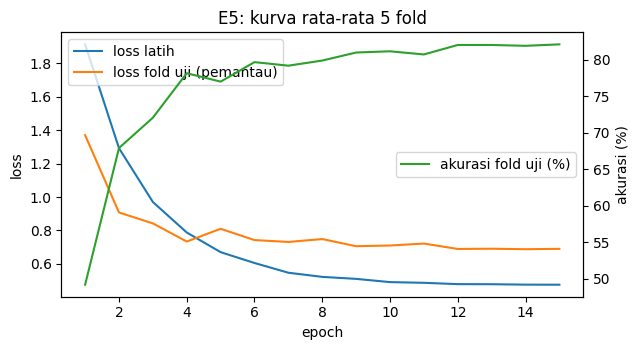

In [27]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    curves = np.stack([np.load(f"{OUT_DIR}/e5_fold{f}.npz", allow_pickle=True)["hist"] for f in range(5)])   # (fold, epoch, [ep, train_loss, test_loss, test_acc])
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6.5, 3.6)); m = curves.mean(0)
    ax.plot(m[:, 0], m[:, 1], label="loss latih"); ax.plot(m[:, 0], m[:, 2], label="loss fold uji (pemantau)"); ax.set_xlabel("epoch"); ax.set_ylabel("loss")
    a2 = ax.twinx(); a2.plot(m[:, 0], m[:, 3], color="tab:green", label="akurasi fold uji (%)"); a2.set_ylabel("akurasi (%)")
    ax.legend(loc="upper left"); a2.legend(loc="center right"); ax.set_title("E5: kurva rata-rata 5 fold"); plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/E5_kurva.png", dpi=150); plt.show()
    pd.DataFrame(curves.reshape(-1, 4), columns=["epoch", "train_loss", "test_loss", "test_acc"]).assign(fold=np.repeat(range(5), curves.shape[1])).to_csv(f"{OUT_DIR}/history_E5.csv", index=False)

### 4. Fusi dengan posterior visual paper vs paper (86,70 %)
Cabang audio diganti logit E5 (epoch terakhir, bersih); cabang visual (bi-LSTM + MLP80) memakai posterior rilisan penulis dengan **fold yang sama persis**. Kepala fusi sama: MinMax → LogReg C=1. Catatan: seperti pada paper, kepala fusi dilatih pada posterior data latih *in-sample*, dan **posterior visual paper juga dipilih dengan fold uji** — keterbatasan ini ikut terbawa dan harus dilaporkan.

In [28]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    from scipy import stats
    from sklearn.svm import SVC
    base = u.fusion_cv(REPO_DIR)                                                                   # replikasi paper (86,70)
    mod_a = wf.make_audio_modify(OUT_DIR)
    e5f = u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp"), modify=mod_a)                # E5: audio E5 + visual paper
    mod_o = u.make_oof_branch(REPO_DIR, lambda: SVC(C=1, probability=True, random_state=u.SEED))      # cabang AU tambahan, posterior out-of-fold
    def mod_both(f, d): mod_a(f, d); mod_o(f, d)
    e5o = u.fusion_cv(REPO_DIR, branches=("audio_e5", "bilstm", "mlp", "au_oof"), modify=mod_both)    # E5 + cabang AU out-of-fold
    def row(name, r, paper=None):
        return [name, paper if paper else round(np.mean(r["acc"]), 2), round(u.ci95(r["acc"]), 2), round(np.mean(r["f1"]), 2), [round(a, 1) for a in r["acc"]]]
    tabF = pd.DataFrame([row("Paper (fusi FT-Wav2Vec2 + bi-LSTM + MLP80)", base, 86.70),
                         row("E5 fusi (audio E5 epoch terakhir + visual paper)", e5f),
                         row("E5 fusi + cabang AU out-of-fold (SVC)", e5o)],
                        columns=["Sistem (pembanding: FUSI)", "Akurasi 5-CV (%)", "±CI95", "F1-macro (%)", "Per fold"])
    for nm, r in [("E5 fusi", e5f), ("E5 fusi + AU OOF", e5o)]:
        d = np.array(r["acc"]) - np.array(base["acc"]); t, p = stats.ttest_rel(r["acc"], base["acc"])
        print(f"{nm}: selisih {d.mean():+.2f} poin | fold lebih baik: {(d > 0).sum()}/5 | paired t p={p:.3f} (pratinjau; n=5 -> daya uji rendah)")
    display(tabF)

E5 fusi: selisih -1.13 poin | fold lebih baik: 1/5 | paired t p=0.159 (pratinjau; n=5 -> daya uji rendah)
E5 fusi + AU OOF: selisih -1.25 poin | fold lebih baik: 2/5 | paired t p=0.242 (pratinjau; n=5 -> daya uji rendah)


,Sistem (pembanding: FUSI),Akurasi 5-CV (%),±CI95,F1-macro (%),Per fold
0,Paper (fusi FT-Wav2Vec2 + bi-LSTM + MLP80),86.70,1.75,86.58,"[88.7, 88.7, 84.7, 85.7, 85.8]"
1,E5 fusi (audio E5 epoch terakhir + visual paper),85.57,1.82,85.17,"[87.0, 87.7, 85.0, 82.3, 85.8]"
2,E5 fusi + cabang AU out-of-fold (SVC),85.45,1.82,85.07,"[86.7, 87.7, 85.3, 81.3, 86.2]"


In [29]:
if not E5_ACTIVE:
    print("E5 dilewati (RUN_E5=False atau tidak ada GPU).")
else:
    if not SMOKE_TEST:
        rows = []
        for name, accs, f1s in [("E5_audio_last", S["acc_last"].values, None), ("E5_audio_bestOnTest", S["acc_best_on_test(cara paper)"].values, None),
                                ("E5_fusion_last", e5f["acc"], e5f["f1"]), ("E5_fusion_AUoof_last", e5o["acc"], e5o["f1"])]:
            rows += [{"experiment": name, "fold": f, "acc": float(accs[f]), "f1_macro": float(f1s[f]) if f1s is not None else np.nan} for f in range(5)]
        u.append_results("results/results_long_m2.csv", rows); tab.to_csv("results/tabel_E5_audio.csv", index=False); tabF.to_csv("results/tabel_E5_fusi.csv", index=False)
        print("Tersimpan di results/. Unduh folder results dari tab Output.")
    else:
        print("SMOKE_TEST: tidak menyimpan hasil.")

Tersimpan di results/. Unduh folder results dari tab Output.


### 5. Cara membaca hasil (jujur)
- "Di atas paper" yang sah = **E5 epoch terakhir** lebih tinggi dari angka paper **dan** selisihnya melebihi CI (≈ ±2 poin) dan konsisten antar-fold. Selisih kecil (< 1 poin) bukan bukti.
- Jika hanya "epoch terbaik pada fold uji" yang melampaui paper, itu belum klaim yang kuat: cara itu optimistis (sama seperti paper).
- Cabang visual belum diperbaiki (masih posterior paper, 62,13 %). Mengalahkan 62,13 % butuh fitur per-frame AU (OpenFace) yang tidak tersedia di repo — itu pekerjaan terpisah.

## 7. Checklist keluaran Minggu 2
- [x] `02_pembanding.ipynb` berisi ≥ 2 eksperimen lengkap (E1–E5, termasuk E3b)
- [x] Diagram alur (`results/flow_eksperimen_M2.png`) dan tabel konfigurasi (`results/tabel_konfigurasi_M2.csv`)
- [x] Kriteria evaluasi (bagian 1) — **perlu persetujuan dosen**
- [x] Skor per fold untuk semua metode (`results/results_long_m2.csv`) → input uji berpasangan Minggu 3
- [x] Kandidat Minggu 3 (`results/kandidat_M3.csv`)